# Análisis de Demanda del Subte de CABA (Líneas A, B y C)
### Preprocesamiento, Análisis Exploratorio de Datos (EDA) y Validación Estadística (2014 - 2019)
**Autor:** Senior Data Scientist & Analista Operativo de Transporte Público
**Proyecto:** Evaluación de la Variación de la Demanda en el Subte de CABA en Días Hábiles y No Laborables

---
## 1. Introducción y Objetivos Metodológicos
El presente análisis tiene como objetivo modelar, contrastar y validar estadísticamente las diferencias de la demanda de pasajeros en la Red de Subterráneos de la Ciudad Autónoma de Buenos Aires (Líneas A, B y C) entre **días hábiles** y **no laborables** (sábados, domingos y feriados nacionales).

Este notebook es el **pipeline completo y único** del proyecto: ejecutado de principio a fin, regenera los datasets procesados (`data_processed/`), todas las tablas (`output/tablas/`) y todos los gráficos (`output/graficos/`).

A lo largo de este notebook se abordan:
1. **Preprocesamiento y Sanitización:** Ingesta por bloques de más de 70 millones de registros de molinete, normalización de esquemas, encodings y nombres de las 44 estaciones de las Líneas A, B y C.
2. **Ingeniería Temporal:** Incorporación del calendario oficial de feriados nacionales de Argentina y discriminación de tipos de día.
3. **Análisis Exploratorio de Datos (EDA):** Perfiles horarios, picos de demanda y estacionalidad mensual con ejes temporales continuos.
4. **Métricas de Retención de Demanda:** Cuantificación del ratio de retención de demanda global, por línea y por estación.
5. **Validación Estadística (Kolmogorov-Smirnov):** Evaluación no paramétrica sobre las 44 estaciones independientes.
6. **Presión de Andén e Implicancias Operativas:** Detección de intervalos críticos de congestión en fines de semana.

In [1]:
# Librerías esenciales
import glob
import os
import unicodedata

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from IPython.display import Markdown, display

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']  # DejaVu como respaldo si Arial no está instalada
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150       # resolución en pantalla
plt.rcParams['savefig.dpi'] = 300      # resolución de los PNG exportados
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [2]:
# =====================================================================
# CONFIGURACIÓN DEL PIPELINE
# =====================================================================
# False: usa los parquet cacheados en data_processed/ si existen.
# True : re-ingesta completa desde los CSV originales en csv/ (~6.7 GB, lento).
FORCE_REPROCESS = False

CSV_DIR = 'csv'
DATA_DIR = 'data_processed'
TABLAS_DIR = os.path.join('output', 'tablas')
GRAFICOS_DIR = os.path.join('output', 'graficos')

PARQUET_15MIN = os.path.join(DATA_DIR, 'subte_consolidado_15min.parquet')
PARQUET_DIARIO = os.path.join(DATA_DIR, 'subte_diario_estaciones.parquet')

for d in (DATA_DIR, TABLAS_DIR, GRAFICOS_DIR):
    os.makedirs(d, exist_ok=True)


def guardar_tabla(nombre, contenido_md, mostrar=True):
    # Escribe una tabla Markdown en output/tablas/ y opcionalmente la renderiza.
    path = os.path.join(TABLAS_DIR, nombre)
    with open(path, 'w', encoding='utf-8') as f:
        f.write(contenido_md)
    print(f"Tabla guardada: {path}")
    if mostrar:
        display(Markdown(contenido_md))


def guardar_figura(nombre, **kwargs):
    # Exporta la figura actual a output/graficos/ (300 DPI) y la muestra.
    path = os.path.join(GRAFICOS_DIR, nombre)
    plt.savefig(path, dpi=300, **kwargs)
    print(f"Gráfico guardado: {path}")
    plt.show()


print("Entorno configurado correctamente.")

Entorno configurado correctamente.


## 2. Ingesta y Preprocesamiento de Datos Crudos
Los registros de molinete se distribuyen en 6 archivos CSV anuales (`csv/historico_AAAA.csv`, ~6.7 GB en total, no versionados). Los archivos presentan **esquemas heterogéneos** entre años: nombres de columnas en mayúsculas/minúsculas, `PAX_TOTAL` vs `TOTAL`, columnas extra (`PERIODO`, `V1`, `ID_ESTACION`), formatos de fecha `YYYY-MM-DD` y `DD/MM/YYYY`, y codificaciones de línea distintas (`B`, `LINEA_B`, `LineaB`).

Para no repetir la ingesta en cada ejecución, el resultado se cachea en formato Parquet en `data_processed/`. La re-ingesta se ejecuta sólo si `FORCE_REPROCESS = True` o si los parquet no existen.

### 2.1. Exploración de Esquemas por Año
Inspección liviana (primeras filas de cada archivo) para documentar las diferencias de esquema. Se omite si los CSV no están disponibles.

In [3]:
csv_files = sorted(glob.glob(os.path.join(CSV_DIR, '*.csv')))

if not csv_files:
    print(f"No se encontraron CSV en '{CSV_DIR}/'. Se omite la exploración de esquemas.")
else:
    esquemas = []
    for f in csv_files:
        muestra = pd.read_csv(f, nrows=5, encoding='latin1')
        esquemas.append({
            'archivo': os.path.basename(f),
            'columnas': ', '.join(muestra.columns),
            'ejemplo_fecha': muestra.filter(regex='(?i)fecha').iloc[0, 0],
            'ejemplo_linea': muestra.filter(regex='(?i)^linea').iloc[0, 0],
        })
    with pd.option_context('display.max_colwidth', None):
        display(pd.DataFrame(esquemas))

,archivo,columnas,ejemplo_fecha,ejemplo_linea
0,historico_2014.csv,"FECHA, DESDE, HASTA, LINEA, MOLINETE, ID_ESTACION, ESTACION, PAX_PAGO, PAX_PASES_PAGOS, PAX_FRANQ, PAX_TOTAL",2014-04-09,B
1,historico_2015.csv,"periodo, fecha, desde, hasta, linea, molinete, estacion, pax_pagos, pax_pases_pagos, pax_franq, total",2015-01-01,LINEA_H
2,historico_2016.csv,"FECHA, DESDE, HASTA, LINEA, MOLINETE, ID_ESTACION, ESTACION, PAX_PAGOS, PAX_PASES_PAGOS, PAX_FREQ, TOTAL",02/01/2016,D
3,historico_2017.csv,"V1, FECHA, DESDE, HASTA, LINEA, MOLINETE, ID_ESTACION, ESTACION, PAX_PAGOS, PAX_PASES_PAGOS, PAX_FREQ, TOTAL",01/01/2017,D
4,historico_2018.csv,"fecha, desde, hasta, linea, molinete, estacion, pax_pagos, pax_pases_pagos, pax_franq, total, periodo",2018-01-01,LineaA
5,historico_2019.csv,"periodo, fecha, desde, hasta, linea, molinete, estacion, pax_pagos, pax_pases_pagos, pax_franq, total",2019-01-01,LineaA


### 2.2. Normalización de Estaciones, Calendario y Tipos de Día
Las 44 estaciones de las Líneas A (18), B (17) y C (9) aparecen con variantes de escritura entre años (mayúsculas, tildes, caracteres mal codificados, sufijos de transbordo como `Callao.B`). Se mapean a un nombre canónico.

Cada fecha se clasifica en uno de **tres tipos de día**, que coinciden con los cronogramas de servicio del operador (hábiles, sábados, y domingos y feriados):
- **Hábil:** lunes a viernes que no son feriado.
- **Sábado:** sábados que no son feriado, y el **Jueves Santo** cuando no coincide con otro feriado (día no laborable optativo, atendido por el operador con horario de sábado).
- **Domingo-Feriado:** domingos y feriados nacionales, incluidos los feriados con fines turísticos (puente).

La clasificación se calcula con una única función (`agregar_calendario`), que se aplica tanto en la ingesta como al cargar los datos cacheados, de modo que un cambio de reglas no requiere re-procesar los CSV. La justificación de las categorías está en `DECISIONES_METODOLOGICAS.md` (DM-03).

In [4]:
# Mapeo de nombres crudos (normalizados a mayúsculas sin tildes) -> nombre canónico
STATION_MAP = {
    # Línea A (18 estaciones, incluyendo Sáenz Peña tratada aparte)
    'ACOYTE': 'Acoyte',
    'ALBERTI': 'Alberti',
    'CARABOBO': 'Carabobo',
    'CASTRO BARROS': 'Castro Barros',
    'CONGRESO': 'Congreso',
    'FLORES': 'San José de Flores',
    'LIMA': 'Lima',
    'LORIA': 'Loria',
    'PASCO': 'Pasco',
    'PERU': 'Perú',
    'PIEDRAS': 'Piedras',
    'PLAZA DE MAYO': 'Plaza de Mayo',
    'PLAZA MISERERE': 'Plaza Miserere',
    'PRIMERA JUNTA': 'Primera Junta',
    'PUAN': 'Puán',
    'RIO DE JANEIRO': 'Río de Janeiro',
    'SAN PEDRITO': 'San Pedrito',

    # Línea B (17 estaciones)
    'ANGEL GALLARDO': 'Ángel Gallardo',
    'CALLAO': 'Callao (B)',
    'CALLAO.B': 'Callao (B)',
    'CARLOS GARDEL': 'Carlos Gardel',
    'CARLOS PELLEGRINI': 'Carlos Pellegrini',
    'DORREGO': 'Dorrego',
    'ECHEVERRIA': 'Echeverría',
    'FEDERICO LACROZE': 'Federico Lacroze',
    'FLORIDA': 'Florida',
    'LEANDRO N. ALEM': 'Leandro N. Alem',
    'LOS INCAS': 'De los Incas',
    'MALABIA': 'Malabia',
    'MEDRANO': 'Medrano',
    'PASTEUR': 'Pasteur',
    'PUEYRREDON': 'Pueyrredón',
    'ROSAS': 'Juan Manuel de Rosas',
    'TRONADOR': 'Tronador',
    'URUGUAY': 'Uruguay',

    # Línea C (9 estaciones)
    'AVENIDA DE MAYO': 'Avenida de Mayo',
    'CONSTITUCION': 'Constitución',
    'DIAGONAL NORTE': 'Diagonal Norte',
    'GENERAL SAN MARTIN': 'General San Martín',
    'INDEPENDENCIA': 'Independencia',
    'LAVALLE': 'Lavalle',
    'MARIANO MORENO': 'Moreno',
    'RETIRO': 'Retiro',
    'SAN JUAN': 'San Juan',
}


def clean_station_name(val):
    if not isinstance(val, str):
        return None
    s = val.strip().upper()
    # Variantes de Sáenz Peña (incluye caracteres mal codificados)
    if 'SAENZ' in s or 'SÁENZ' in s:
        return 'Sáenz Peña'
    # Búsqueda directa
    if s in STATION_MAP:
        return STATION_MAP[s]
    # Búsqueda sin tildes
    s_clean = ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')
    if s_clean in STATION_MAP:
        return STATION_MAP[s_clean]
    # Coincidencia parcial
    for k, v in STATION_MAP.items():
        if k in s or s in k:
            return v
    return s.title()


FERIADOS_AR = holidays.Argentina(years=range(2014, 2020))

DIAS_SEMANA_MAP = {
    0: 'Lunes', 1: 'Martes', 2: 'Miércoles', 3: 'Jueves',
    4: 'Viernes', 5: 'Sábado', 6: 'Domingo'
}
MESES_MAP = {
    1: 'Enero', 2: 'Febrero', 3: 'Marzo', 4: 'Abril', 5: 'Mayo', 6: 'Junio',
    7: 'Julio', 8: 'Agosto', 9: 'Septiembre', 10: 'Octubre', 11: 'Noviembre', 12: 'Diciembre'
}

# Tipos de día (DM-03): coinciden con los cronogramas del operador
TIPOS_DIA = ['Hábil', 'Sábado', 'Domingo-Feriado']
NO_LABORABLES = ['Sábado', 'Domingo-Feriado']
COLUMNAS_CALENDARIO = ['dia_semana', 'dia_semana_nombre', 'mes', 'mes_nombre', 'anio', 'es_feriado', 'tipo_dia']


def calendario(fechas):
    # Variables de calendario por fecha, con las reglas de tipo de día de DM-03.
    cal = pd.DataFrame({'fecha': pd.to_datetime(pd.Series(fechas).drop_duplicates().sort_values().values)})
    nombre = cal['fecha'].dt.date.map(FERIADOS_AR.get)
    # La librería registra las coincidencias como "<feriado>; Jueves Santo":
    # sólo el Jueves Santo que no coincide con otro feriado tiene exactamente este nombre.
    jueves_santo = nombre == 'Jueves Santo'
    cal['dia_semana'] = cal['fecha'].dt.day_of_week  # 0=Lunes, 6=Domingo
    cal['dia_semana_nombre'] = cal['dia_semana'].map(DIAS_SEMANA_MAP)
    cal['mes'] = cal['fecha'].dt.month
    cal['mes_nombre'] = cal['mes'].map(MESES_MAP)
    cal['anio'] = cal['fecha'].dt.year
    cal['es_feriado'] = (nombre.notna() & ~jueves_santo).astype(int)
    cal['tipo_dia'] = np.select(
        [jueves_santo, cal['es_feriado'] == 1, cal['dia_semana'] == 6, cal['dia_semana'] == 5],
        ['Sábado', 'Domingo-Feriado', 'Domingo-Feriado', 'Sábado'],
        default='Hábil'
    )
    return cal


def agregar_calendario(df):
    # Reemplaza las columnas de calendario de df por las calculadas con las reglas vigentes.
    base = df.drop(columns=[c for c in COLUMNAS_CALENDARIO if c in df.columns])
    return base.merge(calendario(base['fecha']), on='fecha', how='left')


print(f"Feriados nacionales cargados (2014-2019): {len(FERIADOS_AR)}")

Feriados nacionales cargados (2014-2019): 110


### 2.3. Ingesta por Bloques, Agregación a 15 Minutos e Ingeniería Temporal
Cada CSV se lee en bloques de 500.000 filas para acotar el uso de memoria. Por bloque se: (1) detectan las columnas relevantes según el esquema del año, (2) filtran las Líneas A, B y C, (3) imputan nulos de ingresos con `0` y (4) agregan los molinetes a nivel **estación × fecha × ventana de 15 min**. Luego se consolidan los bloques, se parsean fechas y se generan las variables de calendario: `dia_semana`, `mes`, `anio`, `hora`, `es_feriado` y `tipo_dia` (`Hábil`, `Sábado` o `Domingo-Feriado`, según las reglas de 2.2).

Como subproducto se genera la tabla de calidad de datos `01_resumen_nulos_limpieza.md`.

In [5]:
FORMATOS_FECHA = ['%Y-%m-%d', '%d/%m/%Y']  # 2014, 2015, 2018, 2019: ISO | 2016, 2017: día/mes/año


def parse_fechas(fecha_str):
    # Parsea fechas con formatos explícitos. No se usa format='mixed' + dayfirst=True porque
    # invierte día y mes en las fechas ISO con día <= 12 (ej. '2015-01-02' -> 1 de febrero).
    unicas = pd.Series(fecha_str.unique())
    parseadas = pd.Series(pd.NaT, index=unicas.index, dtype='datetime64[ns]')
    for fmt in FORMATOS_FECHA:
        parseadas = parseadas.fillna(pd.to_datetime(unicas, format=fmt, errors='coerce'))
    sin_parsear = unicas[parseadas.isna()]
    if len(sin_parsear):
        raise ValueError(f"Fechas con formato no reconocido: {sin_parsear.head(10).tolist()}")
    return fecha_str.map(dict(zip(unicas, parseadas)))


def preprocess_subte():
    print("Iniciando Preprocesamiento de Molinetes Subte CABA (2014-2019)...", flush=True)
    csv_files = sorted(glob.glob(os.path.join(CSV_DIR, '*.csv')))
    if not csv_files:
        raise FileNotFoundError(f"No hay CSV en '{CSV_DIR}/' para re-procesar.")

    total_raw_rows = 0
    total_filtered_rows = 0
    null_counts_by_year = {}
    aggregated_dfs = []
    fechas_por_archivo = {}

    for f in csv_files:
        year_str = os.path.basename(f).replace('.csv', '').replace('historico_', '')
        print(f"\n--- Procesando {f} ({year_str}) ---", flush=True)
        year_raw_rows = 0
        year_filtered_rows = 0
        year_null_ingresos = 0

        for chunk in pd.read_csv(f, chunksize=500000, encoding='latin1', low_memory=False):
            year_raw_rows += len(chunk)

            # Estandarizar nombres de columnas
            chunk.columns = [c.upper().strip().replace('"', '') for c in chunk.columns]

            # Detección de columnas según esquema del año
            l_col = [c for c in chunk.columns if 'LINEA' in c or 'LINE' in c][0]
            s_col = [c for c in chunk.columns if 'ESTACION' in c and 'ID' not in c][0]
            tot_col_matches = [c for c in chunk.columns if 'PAX_TOTAL' in c or c == 'TOTAL']
            tot_col = tot_col_matches[0] if tot_col_matches else 'PAX_TOTAL'
            d_col = [c for c in chunk.columns if 'DESDE' in c][0]
            f_col = [c for c in chunk.columns if 'FECHA' in c][0]

            # Normalizar línea y filtrar A, B, C
            chunk['linea_clean'] = (chunk[l_col].astype(str).str.upper()
                                    .str.replace('LINEA', '', regex=False)
                                    .str.replace('_', '', regex=False).str.strip())
            chunk = chunk[chunk['linea_clean'].isin(['A', 'B', 'C'])].copy()
            if chunk.empty:
                continue
            year_filtered_rows += len(chunk)

            # Nulos en ingresos -> 0
            year_null_ingresos += int(chunk[tot_col].isna().sum())
            chunk['ingresos'] = pd.to_numeric(chunk[tot_col], errors='coerce').fillna(0)

            chunk['estacion_clean'] = chunk[s_col].apply(clean_station_name)
            chunk['ventana_15min'] = chunk[d_col].astype(str).str.strip().str.slice(0, 5)  # HH:MM
            chunk['fecha_str'] = chunk[f_col].astype(str).str.strip()
            fechas_por_archivo.setdefault(year_str, set()).update(chunk['fecha_str'].unique())

            agg_chunk = chunk.groupby(['fecha_str', 'linea_clean', 'estacion_clean', 'ventana_15min'],
                                      as_index=False)['ingresos'].sum()
            aggregated_dfs.append(agg_chunk)

        print(f"Año {year_str}: Filas crudas={year_raw_rows:,} | Filas Líneas A-B-C={year_filtered_rows:,} | Nulos ingresos={year_null_ingresos:,}", flush=True)
        null_counts_by_year[year_str] = {
            'filas_crudas': year_raw_rows,
            'filas_filtradas': year_filtered_rows,
            'nulos_ingresos': year_null_ingresos
        }
        total_raw_rows += year_raw_rows
        total_filtered_rows += year_filtered_rows

    print("\nConsolidando y agregando todos los bloques procesados...", flush=True)
    df_all = pd.concat(aggregated_dfs, ignore_index=True)
    del aggregated_dfs
    # Re-agregar intervalos que quedaron partidos entre bloques
    df_consolidado = df_all.groupby(['fecha_str', 'linea_clean', 'estacion_clean', 'ventana_15min'],
                                    as_index=False)['ingresos'].sum()
    del df_all

    print("Parseando fechas y generando variables de calendario...", flush=True)
    df_consolidado['fecha'] = parse_fechas(df_consolidado['fecha_str'])

    # Validación: cada archivo anual debe contener sólo fechas de su propio año
    for yr, fechas in fechas_por_archivo.items():
        anios = parse_fechas(pd.Series(sorted(fechas))).dt.year
        if not (anios == int(yr)).all():
            raise ValueError(f"historico_{yr}.csv contiene fechas de otros años: {sorted(anios.unique())}")
        print(f"  {yr}: {len(fechas)} fechas únicas, todas dentro del año", flush=True)
    df_consolidado = df_consolidado.drop(columns=['fecha_str'])
    df_consolidado = df_consolidado.sort_values(by=['fecha', 'linea_clean', 'estacion_clean', 'ventana_15min'])
    df_consolidado = df_consolidado.rename(columns={'linea_clean': 'linea', 'estacion_clean': 'estacion'})
    df_consolidado['linea'] = 'Línea ' + df_consolidado['linea']

    # Variables de calendario y tipos de día (2.2, DM-03)
    df_consolidado = agregar_calendario(df_consolidado)
    df_consolidado['hora'] = pd.to_numeric(df_consolidado['ventana_15min'].str.slice(0, 2), errors='coerce').fillna(0).astype(int)

    print(f"\nGuardando dataset procesado en {PARQUET_15MIN}...", flush=True)
    df_consolidado.to_parquet(PARQUET_15MIN, index=False)

    print(f"Guardando agregación diaria en {PARQUET_DIARIO}...", flush=True)
    df_diario = df_consolidado.groupby(
        ['fecha', 'anio', 'mes', 'mes_nombre', 'dia_semana', 'dia_semana_nombre', 'es_feriado', 'tipo_dia', 'linea', 'estacion'],
        as_index=False
    )['ingresos'].sum()
    df_diario.to_parquet(PARQUET_DIARIO, index=False)

    print("\n--- RESUMEN DEL PREPROCESAMIENTO ---")
    print(f"Filas totales en CSVs brutos: {total_raw_rows:,}")
    print(f"Filas filtradas (Líneas A, B, C a nivel molinete): {total_filtered_rows:,}")
    print(f"Registros agregados por estación (15 min): {len(df_consolidado):,}")
    print(f"Registros agregados diarios por estación: {len(df_diario):,}")
    print(f"Total estaciones únicas normalizadas: {df_consolidado['estacion'].nunique()}")

    # Tabla 01: calidad de datos y limpieza
    md_resumen = "# Resumen de Calidad de Datos, Limpieza y Tratamiento de Nulos\n\n"
    md_resumen += "### 1. Ingesta por Año y Detección de Inconsistencias\n\n"
    md_resumen += "| Año | Registros Brutos (Molinete) | Registros Líneas A, B, C | Registros Nulos / NA en Ingresos | % Nulos |\n"
    md_resumen += "| :--- | :---: | :---: | :---: | :---: |\n"
    for yr, data in null_counts_by_year.items():
        pct = (data['nulos_ingresos'] / max(data['filas_filtradas'], 1)) * 100
        md_resumen += f"| {yr} | {data['filas_crudas']:,} | {data['filas_filtradas']:,} | {data['nulos_ingresos']:,} | {pct:.3f}% |\n"
    md_resumen += f"| **Total** | **{total_raw_rows:,}** | **{total_filtered_rows:,}** | **{sum(d['nulos_ingresos'] for d in null_counts_by_year.values()):,}** | **{(sum(d['nulos_ingresos'] for d in null_counts_by_year.values())/total_filtered_rows)*100:.3f}%** |\n\n"

    md_resumen += "### 2. Decisiones de Limpieza y Justificación Metodológica\n\n"
    md_resumen += "1. **Tratamiento de Nulos y Ceros en Ingresos:** Los registros con valor `NA` corresponden a intervalos de 15 minutos en los cuales un molinete físico particular no registró validaciones de pasajeros (inactividad transitoria o fuera de servicio temporal). Siguiendo las directrices operativas de transporte, fueron imputados con valor `0` numérico antes de realizar la suma agregada a nivel estación, garantizando que el cómputo de la estación refleje el flujo exacto sin sesgar positivamente la media.\n"
    md_resumen += "2. **Estandarización de Esquemas y Encodings:** Se corrigieron variaciones entre archivos históricos (encodings mixtos `UTF-8` y `Latin-1`, cabeceras en mayúsculas/minúsculas como `PAX_TOTAL` vs `TOTAL`, y formatos de fecha combinados `YYYY-MM-DD` y `DD/MM/YYYY`).\n"
    md_resumen += "3. **Consolidación de Estaciones (44 estaciones):** Se unificaron variantes de escritura con tildes, caracteres mal codificados (ej. `Sáenz Peña`) y nomenclaturas específicas de transbordo (ej. `Callao.B` $\\to$ `Callao (B)`). Se obtuvo una cobertura perfecta del 100% de las 44 estaciones de las Líneas A, B y C.\n"
    md_resumen += "4. **Agregación por Intervalo de 15 Minutos:** La consolidación de transacciones de molinete en volumen de estación por ventana horaria redujo la cardinalidad de decenas de millones de filas a un dataset estructurado y eficiente de alta performance analítica.\n"
    guardar_tabla('01_resumen_nulos_limpieza.md', md_resumen)

### 2.4. Carga de los Datasets Procesados
Se ejecuta la ingesta sólo si corresponde; en caso contrario se cargan los parquet cacheados. Se deriva además una escala horaria continua (`hora_decimal`, ej. `08:30` → `8.5`) y el subconjunto de horario comercial de servicio (05:00 a 23:45, `df_service`).

In [6]:
if FORCE_REPROCESS or not os.path.exists(PARQUET_15MIN) or not os.path.exists(PARQUET_DIARIO):
    print("Re-procesando CSVs originales..." if FORCE_REPROCESS else "No se encontraron datos procesados. Iniciando ingesta...")
    preprocess_subte()
else:
    print(f"Usando datasets cacheados en '{DATA_DIR}/' (FORCE_REPROCESS = True para re-procesar).")
    print(f"Tabla de calidad de datos (generada en la última ingesta): {os.path.join(TABLAS_DIR, '01_resumen_nulos_limpieza.md')}")

df_15min = pd.read_parquet(PARQUET_15MIN)
df_diario = pd.read_parquet(PARQUET_DIARIO)

# Las variables de calendario se recalculan siempre con las reglas vigentes (2.2),
# de modo que los parquet cacheados no fijen una clasificación anterior.
df_15min = agregar_calendario(df_15min)
df_diario = agregar_calendario(df_diario)

# Escala horaria continua
parts = df_15min['ventana_15min'].str.split(':', expand=True)
df_15min['hora_decimal'] = parts[0].astype(float) + parts[1].astype(float) / 60.0

# Horario operativo del servicio comercial (05:00 a 23:45)
df_service = df_15min[(df_15min['hora_decimal'] >= 5.0) & (df_15min['hora_decimal'] <= 23.75)].copy()

print(f"Registros en dataset 15 min: {len(df_15min):,}")
print(f"Registros en dataset diario: {len(df_diario):,}")
print(f"Estaciones únicas analizadas: {df_15min['estacion'].nunique()}")
display(df_15min.head())

Usando datasets cacheados en 'data_processed/' (FORCE_REPROCESS = True para re-procesar).
Tabla de calidad de datos (generada en la última ingesta): output/tablas/01_resumen_nulos_limpieza.md


Registros en dataset 15 min: 6,485,625
Registros en dataset diario: 94,957
Estaciones únicas analizadas: 44


,linea,estacion,ventana_15min,ingresos,fecha,hora,dia_semana,dia_semana_nombre,mes,mes_nombre,anio,es_feriado,tipo_dia,hora_decimal
0,Línea A,Acoyte,05:00,4.00,2014-01-02,5,3,Jueves,1,Enero,2014,0,Hábil,5.00
1,Línea A,Acoyte,05:15,13.00,2014-01-02,5,3,Jueves,1,Enero,2014,0,Hábil,5.25
2,Línea A,Acoyte,05:30,12.00,2014-01-02,5,3,Jueves,1,Enero,2014,0,Hábil,5.50
3,Línea A,Acoyte,05:45,18.00,2014-01-02,5,3,Jueves,1,Enero,2014,0,Hábil,5.75
4,Línea A,Acoyte,06:00,15.00,2014-01-02,6,3,Jueves,1,Enero,2014,0,Hábil,6.00


### 2.5. Control de Calidad: Coherencia del Calendario
Verificación de que el día de la semana asignado a cada fecha es coherente con la demanda observada. Un domingo (no feriado) cuya demanda total de la red supera el 60% de la de un día hábil típico de ese año es casi con certeza un día hábil mal fechado (por ejemplo, día y mes invertidos al parsear). Se exige que estos casos sean menos del 2% de los domingos en **cada** año.

In [7]:
red_diaria = df_diario.groupby(['fecha', 'anio', 'dia_semana', 'es_feriado'], as_index=False)['ingresos'].sum()
habil_tipico = (red_diaria[(red_diaria['dia_semana'] < 5) & (red_diaria['es_feriado'] == 0)]
                .groupby('anio')['ingresos'].median().rename('habil_tipico'))
domingos = red_diaria[red_diaria['dia_semana'] == 6].join(habil_tipico, on='anio')
domingos['parece_habil'] = domingos['ingresos'] > 0.6 * domingos['habil_tipico']

control_calendario = domingos.groupby('anio').agg(
    domingos=('fecha', 'count'),
    mediana_domingo=('ingresos', 'median'),
    habil_tipico=('habil_tipico', 'first'),
    pct_domingos_tipo_habil=('parece_habil', lambda x: 100 * x.mean()),
)
display(control_calendario.style.format({'mediana_domingo': '{:,.0f}', 'habil_tipico': '{:,.0f}', 'pct_domingos_tipo_habil': '{:.1f}%'}))

assert (control_calendario['pct_domingos_tipo_habil'] < 2).all(), \
    "Domingos con demanda de día hábil: posible error en el parseo de fechas."
print("Control superado: ningún año presenta domingos con demanda de día hábil (< 2%).")

,domingos,mediana_domingo,habil_tipico,pct_domingos_tipo_habil
anio,,,,
2014,52,"66,398","631,928",0.0%
2015,52,"119,391","689,922",0.0%
2016,52,"127,949","724,079",0.0%
2017,53,"137,039","755,311",0.0%
2018,52,"159,266","792,303",0.0%
2019,52,"153,669","748,668",0.0%


Control superado: ningún año presenta domingos con demanda de día hábil (< 2%).


### 2.6. Tipos de Día
Cantidad de fechas de cada tipo de día por año, y excepciones a la regla general (ver 2.2).

In [8]:
dias = calendario(df_diario['fecha'])
display(dias.groupby(['anio', 'tipo_dia']).size().unstack()[TIPOS_DIA]
        .rename_axis(index='Año', columns='Tipo de día'))

nombres = dias['fecha'].dt.date.map(FERIADOS_AR.get).fillna('')
jueves_santo = dias[nombres == 'Jueves Santo']
puentes = dias[nombres.str.contains('turístic')]
print("Jueves Santo no coincidente con otro feriado (-> Sábado): "
      + ', '.join(jueves_santo['fecha'].dt.strftime('%d/%m/%Y')))
print(f"Feriados con fines turísticos (-> Domingo-Feriado): {len(puentes)} días")

Tipo de día,Hábil,Sábado,Domingo-Feriado
Año,,,
2014,244,53,67
2015,245,51,69
2016,247,51,68
2017,247,52,66
2018,244,51,70
2019,244,50,68


Jueves Santo no coincidente con otro feriado (-> Sábado): 17/04/2014, 13/04/2017, 29/03/2018, 18/04/2019
Feriados con fines turísticos (-> Domingo-Feriado): 12 días


## 3. Estadísticas Descriptivas de la Demanda Diaria
Medidas de posición (media, mediana) y dispersión (desvío estándar, rango intercuartílico IQR) del volumen diario de ingresos por estación, desagregadas por línea y tipo de día, más el total de la red.

In [9]:
agg_desc = dict(
    Media='mean',
    Desv_Estandar='std',
    Mediana='median',
    Q25=lambda x: np.percentile(x, 25),
    Q75=lambda x: np.percentile(x, 75),
    Minimo='min',
    Maximo='max',
    Total_Pax='sum'
)
desc_diario = df_diario.groupby(['linea', 'tipo_dia'])['ingresos'].agg(**agg_desc).reset_index()
desc_diario['IQR'] = desc_diario['Q75'] - desc_diario['Q25']

desc_global = df_diario.groupby('tipo_dia')['ingresos'].agg(**agg_desc).reset_index()
desc_global['IQR'] = desc_global['Q75'] - desc_global['Q25']
desc_global['linea'] = 'TOTAL RED (A, B, C)'

desc_final = pd.concat([desc_diario, desc_global], ignore_index=True)
orden_tipo = {t: k for k, t in enumerate(TIPOS_DIA)}
desc_final = desc_final.sort_values(by=['linea', 'tipo_dia'], key=lambda s: s.map(orden_tipo) if s.name == 'tipo_dia' else s,
                                    kind='stable').reset_index(drop=True)

md_desc = "# Estadísticas Descriptivas de Demanda Diaria por Estación\n\n"
md_desc += "Valores expresados en volumen diario de ingresos (pasajeros por estación por día) en el período 2014-2019:\n\n"
md_desc += "| Línea | Tipo de Día | Media Diaria | Desv. Estándar | Mediana | IQR (Q75-Q25) | Mínimo | Máximo | Total Pasajeros |\n"
md_desc += "| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |\n"
for _, r in desc_final.iterrows():
    md_desc += f"| {r['linea']} | {r['tipo_dia']} | {r['Media']:,.1f} | {r['Desv_Estandar']:,.1f} | {r['Mediana']:,.1f} | {r['IQR']:,.1f} | {r['Minimo']:,.0f} | {r['Maximo']:,.0f} | {r['Total_Pax']:,.0f} |\n"

guardar_tabla('02_estadisticas_descriptivas.md', md_desc)

Tabla guardada: output/tablas/02_estadisticas_descriptivas.md


# Estadísticas Descriptivas de Demanda Diaria por Estación

Valores expresados en volumen diario de ingresos (pasajeros por estación por día) en el período 2014-2019:

| Línea | Tipo de Día | Media Diaria | Desv. Estándar | Mediana | IQR (Q75-Q25) | Mínimo | Máximo | Total Pasajeros |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| Línea A | Hábil | 11,761.8 | 6,073.5 | 10,778.0 | 6,503.0 | 0 | 40,470 | 309,112,054 |
| Línea A | Sábado | 4,571.6 | 2,819.6 | 3,959.0 | 2,979.0 | 0 | 28,040 | 25,166,786 |
| Línea A | Domingo-Feriado | 2,139.5 | 1,239.9 | 1,945.0 | 1,484.0 | 0 | 17,395 | 15,640,016 |
| Línea B | Hábil | 18,089.1 | 7,558.4 | 17,400.0 | 10,226.0 | 0 | 46,818 | 449,749,866 |
| Línea B | Sábado | 6,715.3 | 3,648.5 | 6,296.0 | 5,226.8 | 0 | 19,573 | 34,596,978 |
| Línea B | Domingo-Feriado | 3,558.0 | 2,465.9 | 2,996.0 | 3,087.5 | 0 | 18,610 | 22,810,441 |
| Línea C | Hábil | 19,151.9 | 23,941.5 | 8,331.0 | 5,939.2 | 0 | 124,426 | 250,469,109 |
| Línea C | Sábado | 7,837.9 | 11,912.5 | 2,583.0 | 1,996.0 | 0 | 59,938 | 21,405,316 |
| Línea C | Domingo-Feriado | 4,130.9 | 6,119.7 | 1,374.0 | 1,599.8 | 0 | 44,277 | 14,978,665 |
| TOTAL RED (A, B, C) | Hábil | 15,716.3 | 12,841.8 | 12,550.5 | 11,064.8 | 0 | 124,426 | 1,009,331,029 |
| TOTAL RED (A, B, C) | Sábado | 6,062.8 | 6,249.1 | 4,365.5 | 4,734.0 | 0 | 59,938 | 81,169,080 |
| TOTAL RED (A, B, C) | Domingo-Feriado | 3,080.0 | 3,377.8 | 2,117.0 | 2,306.5 | 0 | 44,277 | 53,429,122 |


## 4. Análisis Exploratorio de Datos (EDA)
### 4.1. Curva de Demanda por Día de la Semana y Detección de Horas Pico
Visualización en 2 paneles: Panel A para días hábiles (Lunes a Viernes) con resaltado de horas pico matutina y vespertina; Panel B para sábados y domingos-feriados, contrastados contra la referencia del promedio hábil. El Panel A considera sólo días hábiles (excluye feriados que caen de lunes a viernes).

Gráfico guardado: output/graficos/01_curva_demanda_dia_semana.png


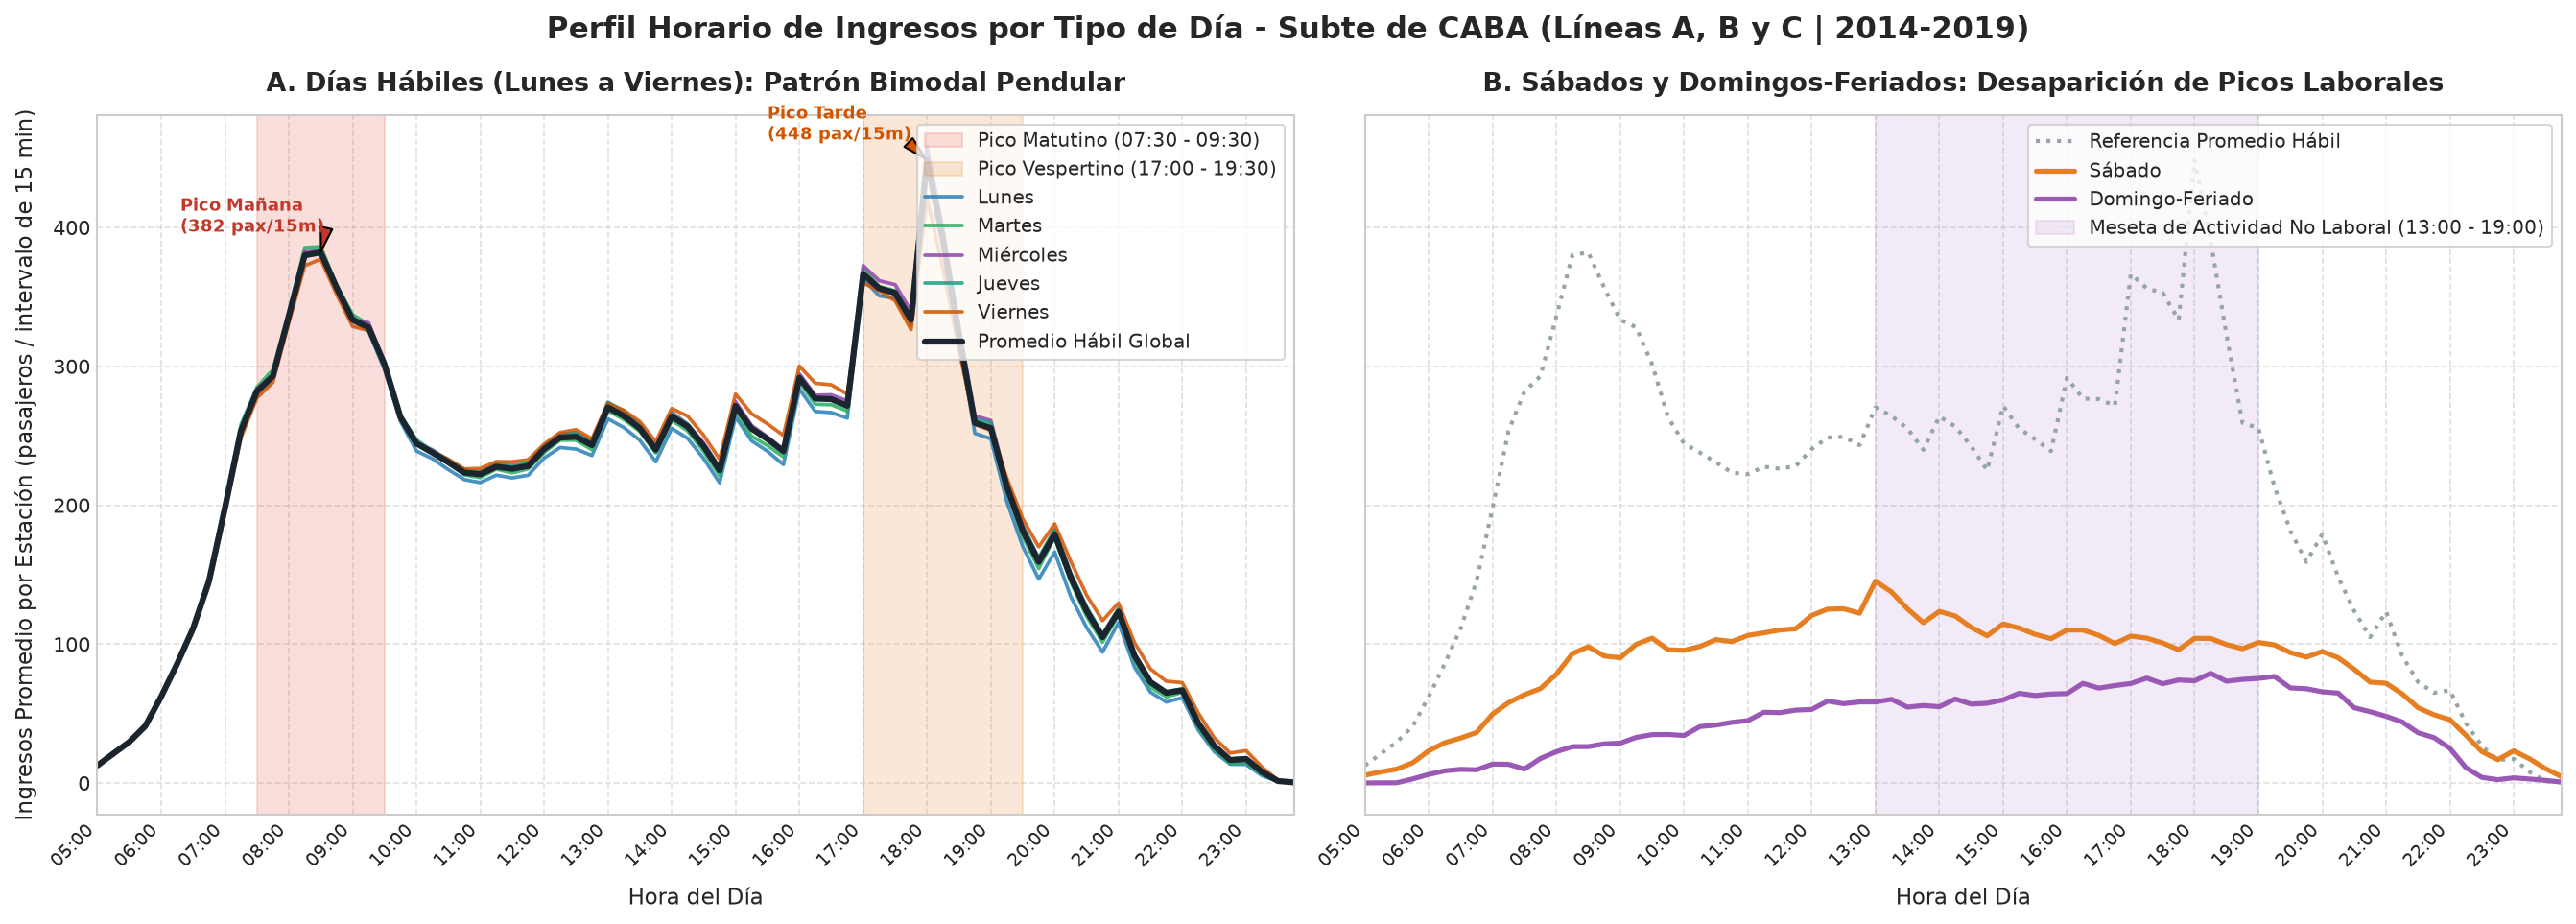

In [10]:
dias_habiles = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes']
line_colors = {'Línea A': '#009ee0', 'Línea B': '#e31b23', 'Línea C': '#005baa'}
TIPO_COLORS = {'Hábil': '#1f77b4', 'Sábado': '#e67e22', 'Domingo-Feriado': '#9b59b6'}
TIPO_ESTILOS = {'Hábil': '-', 'Sábado': '--', 'Domingo-Feriado': ':'}

hourly_day = df_service[df_service['tipo_dia'] == 'Hábil'].groupby(['dia_semana_nombre', 'hora_decimal'])['ingresos'].mean().reset_index()
hourly_tipo = df_service.groupby(['tipo_dia', 'hora_decimal'])['ingresos'].mean().reset_index()
hourly_habil_mean = df_service[df_service['tipo_dia'] == 'Hábil'].groupby('hora_decimal')['ingresos'].mean().reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5), sharey=True)

# --- PANEL A: DÍAS HÁBILES ---
ax1.axvspan(7.5, 9.5, color='#e74c3c', alpha=0.18, label='Pico Matutino (07:30 - 09:30)')
ax1.axvspan(17.0, 19.5, color='#e67e22', alpha=0.18, label='Pico Vespertino (17:00 - 19:30)')

habiles_colors = {'Lunes': '#2980b9', 'Martes': '#27ae60', 'Miércoles': '#8e44ad', 'Jueves': '#16a085', 'Viernes': '#d35400'}
for d in dias_habiles:
    sub = hourly_day[hourly_day['dia_semana_nombre'] == d].sort_values(by='hora_decimal')
    ax1.plot(sub['hora_decimal'], sub['ingresos'], label=d, color=habiles_colors[d], linewidth=1.8, alpha=0.85)

ax1.plot(hourly_habil_mean['hora_decimal'], hourly_habil_mean['ingresos'],
         label='Promedio Hábil Global', color='#1a252f', linewidth=3.0, linestyle='-')

ax1.set_title('A. Días Hábiles (Lunes a Viernes): Patrón Bimodal Pendular', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('Hora del Día', fontsize=11, labelpad=8)
ax1.set_ylabel('Ingresos Promedio por Estación (pasajeros / intervalo de 15 min)', fontsize=11, labelpad=8)
ax1.set_xlim(5.0, 23.75)
hours_ticks = np.arange(5, 24, 1)
hours_labels = [f'{int(h):02d}:00' for h in hours_ticks]
ax1.set_xticks(hours_ticks)
ax1.set_xticklabels(hours_labels, rotation=45, ha='right', fontsize=9)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right', frameon=True, fontsize=9.5)

# Anotaciones de picos
peak_mat = hourly_habil_mean[(hourly_habil_mean['hora_decimal'] >= 7.5) & (hourly_habil_mean['hora_decimal'] <= 9.5)].sort_values(by='ingresos', ascending=False).iloc[0]
peak_vesp = hourly_habil_mean[(hourly_habil_mean['hora_decimal'] >= 17.0) & (hourly_habil_mean['hora_decimal'] <= 19.5)].sort_values(by='ingresos', ascending=False).iloc[0]
ax1.annotate(f'Pico Mañana\n({peak_mat["ingresos"]:.0f} pax/15m)',
             xy=(peak_mat['hora_decimal'], peak_mat['ingresos']),
             xytext=(peak_mat['hora_decimal'] - 2.2, peak_mat['ingresos'] + 15),
             arrowprops=dict(facecolor='#c0392b', shrink=0.08, width=1.5, headwidth=6),
             fontsize=8.5, fontweight='bold', color='#c0392b')
ax1.annotate(f'Pico Tarde\n({peak_vesp["ingresos"]:.0f} pax/15m)',
             xy=(peak_vesp['hora_decimal'], peak_vesp['ingresos']),
             xytext=(peak_vesp['hora_decimal'] - 2.5, peak_vesp['ingresos'] + 15),
             arrowprops=dict(facecolor='#d35400', shrink=0.08, width=1.5, headwidth=6),
             fontsize=8.5, fontweight='bold', color='#d35400')

# --- PANEL B: SÁBADOS Y DOMINGOS-FERIADOS VS HÁBIL ---
ax2.plot(hourly_habil_mean['hora_decimal'], hourly_habil_mean['ingresos'],
         label='Referencia Promedio Hábil', color='#95a5a6', linewidth=2.0, linestyle=':')
for t in NO_LABORABLES:
    sub_t = hourly_tipo[hourly_tipo['tipo_dia'] == t].sort_values(by='hora_decimal')
    ax2.plot(sub_t['hora_decimal'], sub_t['ingresos'], label=t, color=TIPO_COLORS[t], linewidth=2.5)
ax2.axvspan(13.0, 19.0, color='#9b59b6', alpha=0.12, label='Meseta de Actividad No Laboral (13:00 - 19:00)')

ax2.set_title('B. Sábados y Domingos-Feriados: Desaparición de Picos Laborales', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel('Hora del Día', fontsize=11, labelpad=8)
ax2.set_xlim(5.0, 23.75)
ax2.set_xticks(hours_ticks)
ax2.set_xticklabels(hours_labels, rotation=45, ha='right', fontsize=9)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper right', frameon=True, fontsize=9.5)

plt.suptitle('Perfil Horario de Ingresos por Tipo de Día - Subte de CABA (Líneas A, B y C | 2014-2019)',
             fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
guardar_figura('01_curva_demanda_dia_semana.png', bbox_inches='tight')

### 4.2. Curvas de Demanda por Mes (Estacionalidad Anual)
Comportamiento del promedio diario de ingresos por estación a lo largo de los doce meses del año, por línea y, para la red consolidada, por tipo de día.

Gráfico guardado: output/graficos/02_curva_demanda_estacional_mes.png


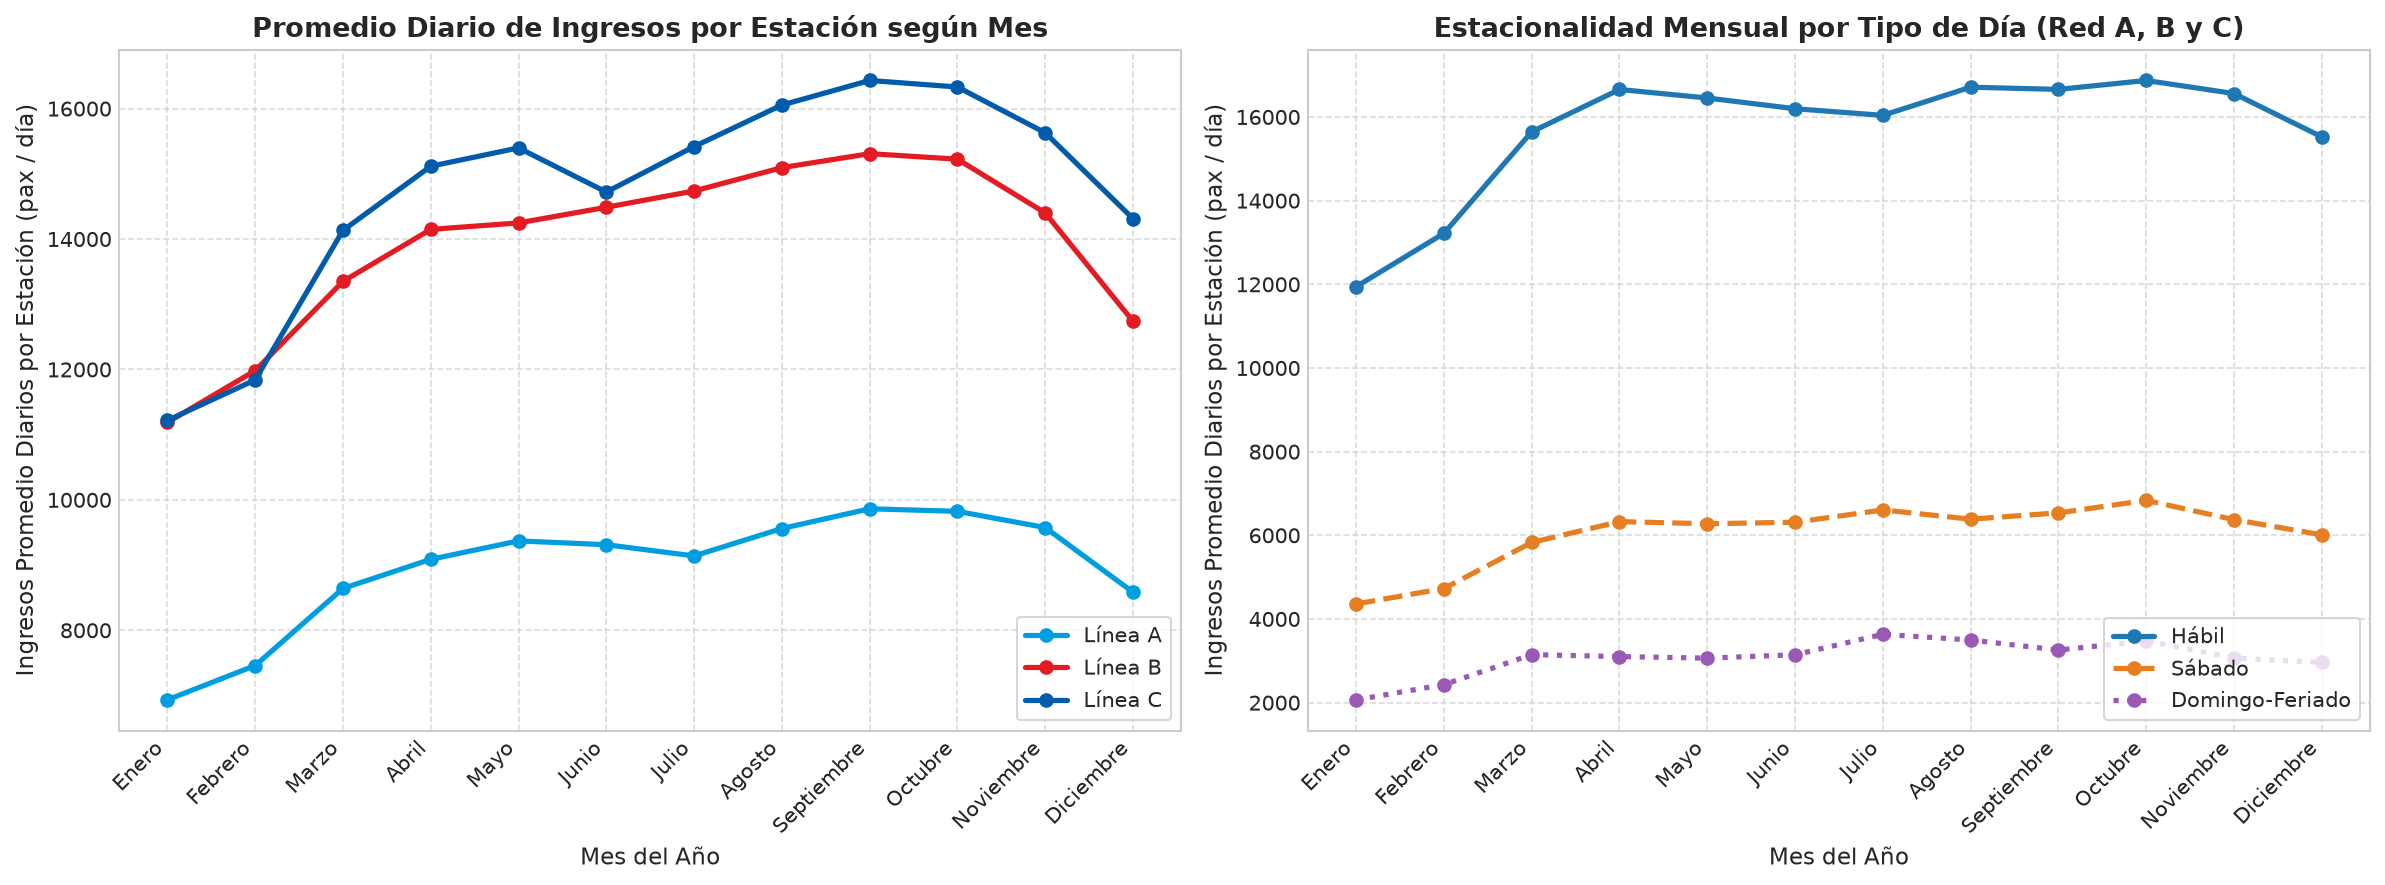

In [11]:
meses_orden = list(MESES_MAP.values())
monthly_line = df_diario.groupby(['mes', 'mes_nombre', 'linea'])['ingresos'].mean().reset_index()
monthly_line['mes_idx'] = monthly_line['mes'] - 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Izquierda: por línea
for l in sorted(monthly_line['linea'].unique()):
    sub = monthly_line[monthly_line['linea'] == l].sort_values(by='mes')
    ax1.plot(sub['mes_idx'], sub['ingresos'], marker='o', linewidth=2.5, label=l, color=line_colors.get(l, None))

ax1.set_title('Promedio Diario de Ingresos por Estación según Mes', fontsize=13, fontweight='bold')
ax1.set_xlabel('Mes del Año', fontsize=11)
ax1.set_ylabel('Ingresos Promedio Diarios por Estación (pax / día)', fontsize=11)
ax1.set_xticks(range(12))
ax1.set_xticklabels(meses_orden, rotation=45, ha='right')
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend(loc='lower right', frameon=True)

# Derecha: red consolidada por tipo de día
monthly_tipo = df_diario.groupby(['mes', 'tipo_dia'])['ingresos'].mean().reset_index()
for t in TIPOS_DIA:
    sub = monthly_tipo[monthly_tipo['tipo_dia'] == t].sort_values(by='mes')
    ax2.plot(sub['mes'] - 1, sub['ingresos'], marker='o', linewidth=2.5, label=t,
             color=TIPO_COLORS[t], linestyle=TIPO_ESTILOS[t])
ax2.set_title('Estacionalidad Mensual por Tipo de Día (Red A, B y C)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Mes del Año', fontsize=11)
ax2.set_ylabel('Ingresos Promedio Diarios por Estación (pax / día)', fontsize=11)
ax2.set_xticks(range(12))
ax2.set_xticklabels(meses_orden, rotation=45, ha='right')
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend(loc='lower right', frameon=True)

plt.tight_layout()
guardar_figura('02_curva_demanda_estacional_mes.png')

### 4.3. Perfil Horario Desagregado por Línea y Tipo de Día
Perfil promedio de ingresos por estación en intervalos de 15 minutos, de forma independiente para cada línea.

Gráfico guardado: output/graficos/03_perfil_horario_por_linea.png


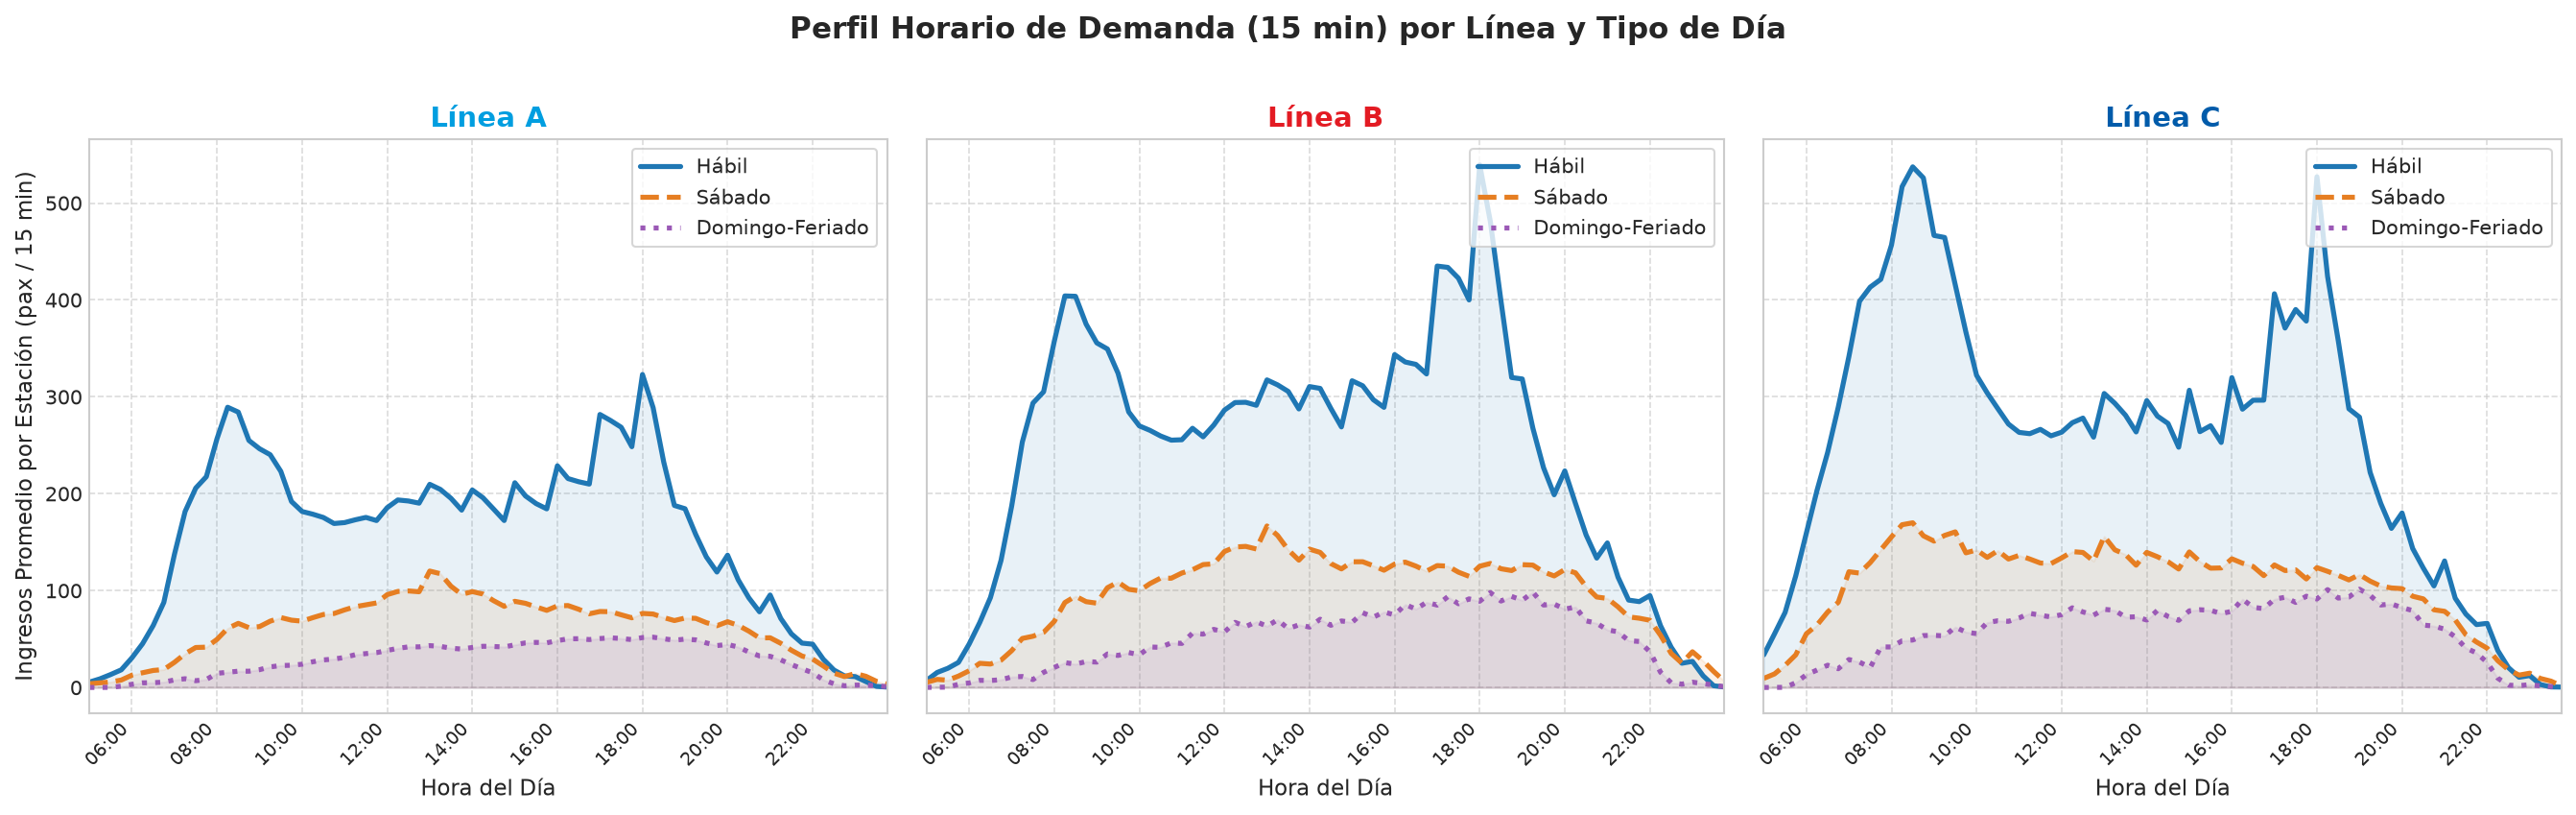

In [12]:
hourly_line_type = df_service.groupby(['linea', 'tipo_dia', 'hora_decimal'])['ingresos'].mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for i, l in enumerate(['Línea A', 'Línea B', 'Línea C']):
    ax = axes[i]
    for t in TIPOS_DIA:
        sub = hourly_line_type[(hourly_line_type['linea'] == l) & (hourly_line_type['tipo_dia'] == t)].sort_values(by='hora_decimal')
        ax.plot(sub['hora_decimal'], sub['ingresos'], label=t, color=TIPO_COLORS[t], linewidth=2.5, linestyle=TIPO_ESTILOS[t])
        ax.fill_between(sub['hora_decimal'], sub['ingresos'], alpha=0.10, color=TIPO_COLORS[t])

    ax.set_title(f'{l}', fontsize=14, fontweight='bold', color=line_colors.get(l, 'black'))
    ax.set_xlabel('Hora del Día', fontsize=11)
    if i == 0:
        ax.set_ylabel('Ingresos Promedio por Estación (pax / 15 min)', fontsize=11)
    ax.set_xlim(5.0, 23.75)
    step_ticks = np.arange(6, 24, 2)
    ax.set_xticks(step_ticks)
    ax.set_xticklabels([f'{int(h):02d}:00' for h in step_ticks], rotation=45, ha='right', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper right', frameon=True)

plt.suptitle('Perfil Horario de Demanda (15 min) por Línea y Tipo de Día', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
guardar_figura('03_perfil_horario_por_linea.png', bbox_inches='tight')

### 4.4. Comparativa por Tipo de Día en Estaciones Representativas
Contraste en cuatro nodos de alta transferencia: Constitución, Retiro, Carlos Pellegrini y San Pedrito.

Gráfico guardado: output/graficos/04_comparativa_habil_nolab_estaciones_clave.png


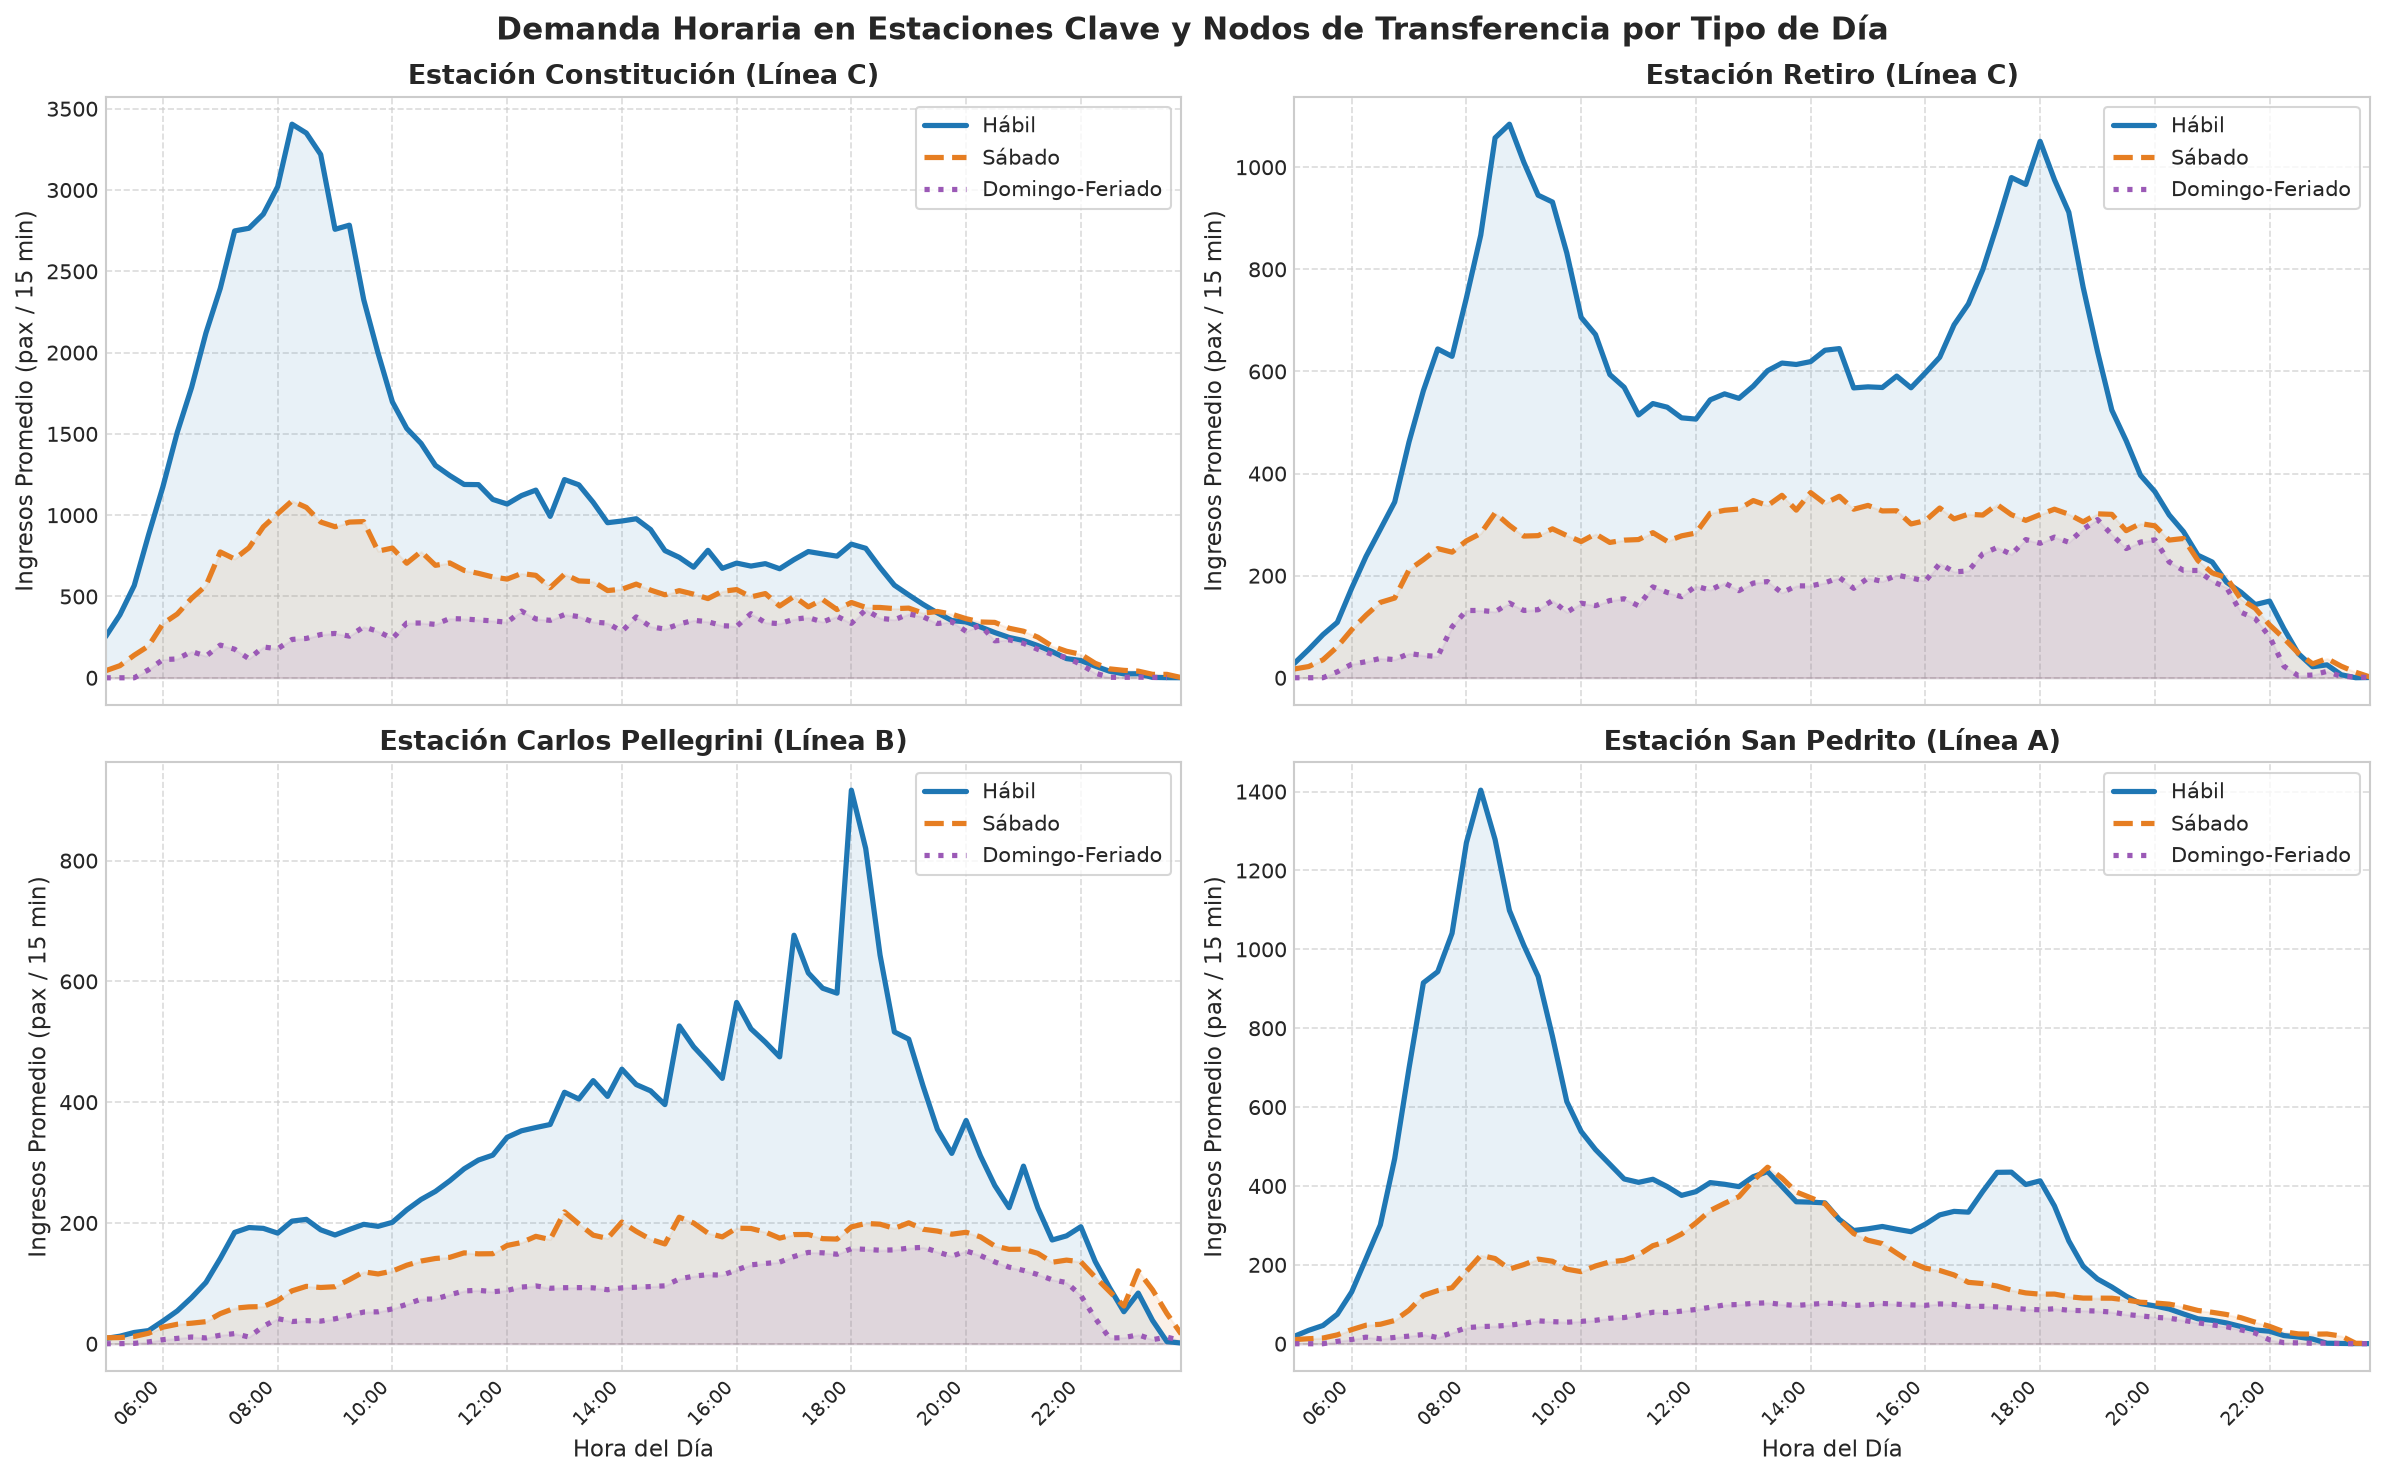

In [13]:
estaciones_clave = ['Constitución', 'Retiro', 'Carlos Pellegrini', 'San Pedrito']
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
axes = axes.flatten()

for i, est in enumerate(estaciones_clave):
    ax = axes[i]
    sub = df_service[df_service['estacion'] == est]
    st_agg = sub.groupby(['tipo_dia', 'hora_decimal'])['ingresos'].mean().reset_index()
    for t in TIPOS_DIA:
        st_t = st_agg[st_agg['tipo_dia'] == t].sort_values(by='hora_decimal')
        ax.plot(st_t['hora_decimal'], st_t['ingresos'], label=t, color=TIPO_COLORS[t], linewidth=2.5, linestyle=TIPO_ESTILOS[t])
        ax.fill_between(st_t['hora_decimal'], st_t['ingresos'], alpha=0.10, color=TIPO_COLORS[t])

    ax.set_title(f'Estación {est} ({sub["linea"].iloc[0]})', fontsize=13, fontweight='bold')
    ax.set_ylabel('Ingresos Promedio (pax / 15 min)', fontsize=11)
    ax.set_xlim(5.0, 23.75)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper right', frameon=True)
    if i >= 2:
        ax.set_xlabel('Hora del Día', fontsize=11)
        step_ticks = np.arange(6, 24, 2)
        ax.set_xticks(step_ticks)
        ax.set_xticklabels([f'{int(h):02d}:00' for h in step_ticks], rotation=45, ha='right', fontsize=9)

plt.suptitle('Demanda Horaria en Estaciones Clave y Nodos de Transferencia por Tipo de Día', fontsize=15, fontweight='bold')
plt.tight_layout()
guardar_figura('04_comparativa_habil_nolab_estaciones_clave.png')

## 5. Ratios de Retención de Demanda
El Ratio de Retención mide la proporción de la demanda de los días hábiles que se mantiene en cada tipo de día no laborable $t$ (Sábado; Domingo-Feriado):
$$\text{Ratio de Retención}_t\,(\%) = \frac{\overline{\text{Ingresos Diarios}}_{t}}{\overline{\text{Ingresos Diarios}}_{\text{Hábil}}} \times 100$$

### 5.1. Por Línea y Total de la Red

In [14]:
linea_promedios = df_diario.groupby(['linea', 'tipo_dia'])['ingresos'].mean().unstack()[TIPOS_DIA]
red_promedios = df_diario.groupby('tipo_dia')['ingresos'].mean()[TIPOS_DIA].rename('TOTAL RED (A, B, C)')
ret_linea = pd.concat([linea_promedios, red_promedios.to_frame().T])
for t in NO_LABORABLES:
    ret_linea[f'ret_{t}'] = ret_linea[t] / ret_linea['Hábil'] * 100

md_ret_linea = "# Ratios de Retención de Demanda por Línea y Tipo de Día\n\n"
md_ret_linea += "El Ratio de Retención mide la proporción de la demanda de los días hábiles que se mantiene en cada tipo de día no laborable (Sábado; Domingo-Feriado):\n"
md_ret_linea += "$$\\text{Ratio de Retención}_t\\,(\\%) = \\frac{\\overline{\\text{Ingresos Diarios}}_{t}}{\\overline{\\text{Ingresos Diarios}}_{\\text{Hábil}}} \\times 100$$\n\n"
md_ret_linea += "| Línea | Promedio Hábil (pax/estación) | Promedio Sábado (pax/estación) | Retención Sábado (%) | Promedio Domingo-Feriado (pax/estación) | Retención Domingo-Feriado (%) |\n"
md_ret_linea += "| :--- | :---: | :---: | :---: | :---: | :---: |\n"
for l, r in ret_linea.iterrows():
    b = '**' if l.startswith('TOTAL') else ''
    md_ret_linea += (f"| {b}{l}{b} | {b}{r['Hábil']:,.1f}{b} | {b}{r['Sábado']:,.1f}{b} | **{r['ret_Sábado']:.2f}%** "
                     f"| {b}{r['Domingo-Feriado']:,.1f}{b} | **{r['ret_Domingo-Feriado']:.2f}%** |\n")

guardar_tabla('03_ratios_retencion_linea.md', md_ret_linea)

Tabla guardada: output/tablas/03_ratios_retencion_linea.md


# Ratios de Retención de Demanda por Línea y Tipo de Día

El Ratio de Retención mide la proporción de la demanda de los días hábiles que se mantiene en cada tipo de día no laborable (Sábado; Domingo-Feriado):
$$\text{Ratio de Retención}_t\,(\%) = \frac{\overline{\text{Ingresos Diarios}}_{t}}{\overline{\text{Ingresos Diarios}}_{\text{Hábil}}} \times 100$$

| Línea | Promedio Hábil (pax/estación) | Promedio Sábado (pax/estación) | Retención Sábado (%) | Promedio Domingo-Feriado (pax/estación) | Retención Domingo-Feriado (%) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Línea A | 11,761.8 | 4,571.6 | **38.87%** | 2,139.5 | **18.19%** |
| Línea B | 18,089.1 | 6,715.3 | **37.12%** | 3,558.0 | **19.67%** |
| Línea C | 19,151.9 | 7,837.9 | **40.92%** | 4,130.9 | **21.57%** |
| **TOTAL RED (A, B, C)** | **15,716.3** | **6,062.8** | **38.58%** | **3,080.0** | **19.60%** |


La categoría *Domingo-Feriado* agrupa domingos y feriados nacionales (ver 2.2). Para verificar que ambos componentes tienen un nivel de demanda comparable, se desagrega su retención:

In [15]:
tipo_dia_detalle = np.where(df_diario['tipo_dia'] != 'Domingo-Feriado', df_diario['tipo_dia'],
                            np.where(df_diario['es_feriado'] == 1, 'Feriado', 'Domingo'))
ret_tipo_dia = (df_diario.groupby(tipo_dia_detalle)['ingresos'].mean()
                .reindex(['Hábil', 'Sábado', 'Domingo', 'Feriado'])
                .to_frame('promedio_diario_por_estacion'))
ret_tipo_dia['ratio_retencion_pct'] = ret_tipo_dia['promedio_diario_por_estacion'] / ret_tipo_dia.loc['Hábil', 'promedio_diario_por_estacion'] * 100
display(ret_tipo_dia.style.format({'promedio_diario_por_estacion': '{:,.1f}', 'ratio_retencion_pct': '{:.2f}%'}))

,promedio_diario_por_estacion,ratio_retencion_pct
Hábil,"15,716.3",100.00%
Sábado,"6,062.8",38.58%
Domingo,"2,951.7",18.78%
Feriado,"3,449.8",21.95%


### 5.2. Por Estación (Top 5 / Bottom 5 y Tabla Completa)

In [16]:
est_promedios = df_diario.groupby(['linea', 'estacion', 'tipo_dia'])['ingresos'].mean().unstack()[TIPOS_DIA].reset_index()
for t in NO_LABORABLES:
    est_promedios[f'ret_{t}'] = est_promedios[t] / est_promedios['Hábil'] * 100

md_ret_est = "# Ratios de Retención de Demanda por Estación y Tipo de Día (44 Estaciones)\n\n"
for t in NO_LABORABLES:
    orden = est_promedios.sort_values(by=f'ret_{t}', ascending=False)
    for titulo, sub in [(f"Top 5 Estaciones con Mayor Retención en {t}", orden.head(5)),
                        (f"Top 5 Estaciones con Menor Retención en {t}", orden.tail(5).iloc[::-1])]:
        md_ret_est += f"### {titulo}\n\n"
        md_ret_est += f"| Ranking | Estación | Línea | Promedio Hábil | Promedio {t} | Retención {t} (%) |\n"
        md_ret_est += "| :---: | :--- | :--- | :---: | :---: | :---: |\n"
        for k, (_, r) in enumerate(sub.iterrows(), 1):
            md_ret_est += f"| {k} | **{r['estacion']}** | {r['linea']} | {r['Hábil']:,.1f} | {r[t]:,.1f} | **{r[f'ret_{t}']:.2f}%** |\n"
        md_ret_est += "\n"

md_ret_est += "### Tabla Completa de las 44 Estaciones (ordenada por retención en Domingo-Feriado)\n\n"
md_ret_est += "| # | Estación | Línea | Promedio Hábil | Promedio Sábado | Retención Sábado (%) | Promedio Domingo-Feriado | Retención Domingo-Feriado (%) |\n"
md_ret_est += "| :---: | :--- | :--- | :---: | :---: | :---: | :---: | :---: |\n"
for k, (_, r) in enumerate(est_promedios.sort_values(by='ret_Domingo-Feriado', ascending=False).iterrows(), 1):
    md_ret_est += (f"| {k} | {r['estacion']} | {r['linea']} | {r['Hábil']:,.1f} | {r['Sábado']:,.1f} | {r['ret_Sábado']:.2f}% "
                   f"| {r['Domingo-Feriado']:,.1f} | {r['ret_Domingo-Feriado']:.2f}% |\n")

guardar_tabla('04_ratios_retencion_top_bottom_estaciones.md', md_ret_est)

Tabla guardada: output/tablas/04_ratios_retencion_top_bottom_estaciones.md


# Ratios de Retención de Demanda por Estación y Tipo de Día (44 Estaciones)

### Top 5 Estaciones con Mayor Retención en Sábado

| Ranking | Estación | Línea | Promedio Hábil | Promedio Sábado | Retención Sábado (%) |
| :---: | :--- | :--- | :---: | :---: | :---: |
| 1 | **Carlos Gardel** | Línea B | 15,026.8 | 10,862.2 | **72.29%** |
| 2 | **Alberti** | Línea A | 4,745.5 | 2,569.3 | **54.14%** |
| 3 | **Plaza Miserere** | Línea A | 14,489.0 | 7,680.7 | **53.01%** |
| 4 | **Pueyrredón** | Línea B | 13,927.9 | 7,066.1 | **50.73%** |
| 5 | **Independencia** | Línea C | 6,264.3 | 2,960.6 | **47.26%** |

### Top 5 Estaciones con Menor Retención en Sábado

| Ranking | Estación | Línea | Promedio Hábil | Promedio Sábado | Retención Sábado (%) |
| :---: | :--- | :--- | :---: | :---: | :---: |
| 1 | **Diagonal Norte** | Línea C | 6,989.0 | 1,306.7 | **18.70%** |
| 2 | **Plaza de Mayo** | Línea A | 20,572.1 | 3,859.1 | **18.76%** |
| 3 | **Florida** | Línea B | 23,425.8 | 4,574.9 | **19.53%** |
| 4 | **Moreno** | Línea C | 8,201.3 | 1,693.3 | **20.65%** |
| 5 | **Piedras** | Línea A | 8,286.4 | 1,846.8 | **22.29%** |

### Top 5 Estaciones con Mayor Retención en Domingo-Feriado

| Ranking | Estación | Línea | Promedio Hábil | Promedio Domingo-Feriado | Retención Domingo-Feriado (%) |
| :---: | :--- | :--- | :---: | :---: | :---: |
| 1 | **Carlos Gardel** | Línea B | 15,026.8 | 8,135.3 | **54.14%** |
| 2 | **Independencia** | Línea C | 6,264.3 | 1,984.9 | **31.69%** |
| 3 | **Retiro** | Línea C | 38,731.0 | 10,899.6 | **28.14%** |
| 4 | **Carlos Pellegrini** | Línea B | 22,642.4 | 5,777.7 | **25.52%** |
| 5 | **Loria** | Línea A | 7,720.0 | 1,917.6 | **24.84%** |

### Top 5 Estaciones con Menor Retención en Domingo-Feriado

| Ranking | Estación | Línea | Promedio Hábil | Promedio Domingo-Feriado | Retención Domingo-Feriado (%) |
| :---: | :--- | :--- | :---: | :---: | :---: |
| 1 | **Florida** | Línea B | 23,425.8 | 2,117.4 | **9.04%** |
| 2 | **Diagonal Norte** | Línea C | 6,989.0 | 641.7 | **9.18%** |
| 3 | **Piedras** | Línea A | 8,286.4 | 885.3 | **10.68%** |
| 4 | **Moreno** | Línea C | 8,201.3 | 920.5 | **11.22%** |
| 5 | **Plaza de Mayo** | Línea A | 20,572.1 | 2,377.4 | **11.56%** |

### Tabla Completa de las 44 Estaciones (ordenada por retención en Domingo-Feriado)

| # | Estación | Línea | Promedio Hábil | Promedio Sábado | Retención Sábado (%) | Promedio Domingo-Feriado | Retención Domingo-Feriado (%) |
| :---: | :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| 1 | Carlos Gardel | Línea B | 15,026.8 | 10,862.2 | 72.29% | 8,135.3 | 54.14% |
| 2 | Independencia | Línea C | 6,264.3 | 2,960.6 | 47.26% | 1,984.9 | 31.69% |
| 3 | Retiro | Línea C | 38,731.0 | 18,222.7 | 47.05% | 10,899.6 | 28.14% |
| 4 | Carlos Pellegrini | Línea B | 22,642.4 | 9,258.5 | 40.89% | 5,777.7 | 25.52% |
| 5 | Loria | Línea A | 7,720.0 | 3,618.9 | 46.88% | 1,917.6 | 24.84% |
| 6 | Plaza Miserere | Línea A | 14,489.0 | 7,680.7 | 53.01% | 3,393.5 | 23.42% |
| 7 | Ángel Gallardo | Línea B | 15,971.6 | 6,500.9 | 40.70% | 3,713.1 | 23.25% |
| 8 | Alberti | Línea A | 4,745.5 | 2,569.3 | 54.14% | 1,094.9 | 23.07% |
| 9 | Acoyte | Línea A | 14,266.7 | 6,619.5 | 46.40% | 3,286.7 | 23.04% |
| 10 | Medrano | Línea B | 18,114.5 | 7,681.1 | 42.40% | 4,099.3 | 22.63% |
| 11 | Constitución | Línea C | 79,064.7 | 37,172.7 | 47.02% | 17,760.8 | 22.46% |
| 12 | Castro Barros | Línea A | 9,423.4 | 4,348.9 | 46.15% | 2,103.4 | 22.32% |
| 13 | Río de Janeiro | Línea A | 10,562.4 | 4,735.4 | 44.83% | 2,303.2 | 21.81% |
| 14 | San Juan | Línea C | 6,318.2 | 2,449.9 | 38.78% | 1,309.9 | 20.73% |
| 15 | Dorrego | Línea B | 13,654.1 | 5,478.9 | 40.13% | 2,775.1 | 20.32% |
| 16 | Malabia | Línea B | 20,603.2 | 8,378.7 | 40.67% | 4,127.1 | 20.03% |
| 17 | Primera Junta | Línea A | 13,084.5 | 5,685.3 | 43.45% | 2,602.3 | 19.89% |
| 18 | Congreso | Línea A | 13,880.2 | 5,481.8 | 39.49% | 2,723.7 | 19.62% |
| 19 | San José de Flores | Línea A | 11,734.3 | 4,996.4 | 42.58% | 2,298.6 | 19.59% |
| 20 | Pasco | Línea A | 3,803.1 | 1,511.8 | 39.75% | 737.3 | 19.39% |
| 21 | Lima | Línea A | 8,234.3 | 2,935.0 | 35.64% | 1,594.5 | 19.36% |
| 22 | Echeverría | Línea B | 7,240.4 | 2,534.6 | 35.01% | 1,393.5 | 19.25% |
| 23 | Carabobo | Línea A | 11,631.5 | 4,875.1 | 41.91% | 2,222.6 | 19.11% |
| 24 | Federico Lacroze | Línea B | 30,264.7 | 11,696.2 | 38.65% | 5,772.8 | 19.07% |
| 25 | De los Incas | Línea B | 11,547.2 | 4,106.0 | 35.56% | 2,135.2 | 18.49% |
| 26 | Avenida de Mayo | Línea C | 6,534.5 | 2,041.0 | 31.23% | 1,195.2 | 18.29% |
| 27 | Juan Manuel de Rosas | Línea B | 27,969.2 | 10,146.1 | 36.28% | 5,083.1 | 18.17% |
| 28 | Puán | Línea A | 7,257.8 | 2,824.1 | 38.91% | 1,282.2 | 17.67% |
| 29 | Callao (B) | Línea B | 19,752.5 | 6,852.2 | 34.69% | 3,431.6 | 17.37% |
| 30 | Leandro N. Alem | Línea B | 27,965.5 | 6,938.2 | 24.81% | 4,495.1 | 16.07% |
| 31 | Pueyrredón | Línea B | 13,927.9 | 7,066.1 | 50.73% | 2,228.1 | 16.00% |
| 32 | San Pedrito | Línea A | 27,566.5 | 12,385.9 | 44.93% | 4,375.7 | 15.87% |
| 33 | Tronador | Línea B | 6,208.7 | 2,009.7 | 32.37% | 967.9 | 15.59% |
| 34 | Sáenz Peña | Línea A | 9,897.5 | 2,816.5 | 28.46% | 1,400.7 | 14.15% |
| 35 | General San Martín | Línea C | 10,642.5 | 2,679.5 | 25.18% | 1,426.1 | 13.40% |
| 36 | Pasteur | Línea B | 14,279.3 | 5,575.5 | 39.05% | 1,872.4 | 13.11% |
| 37 | Lavalle | Línea C | 10,981.7 | 2,992.5 | 27.25% | 1,419.4 | 12.93% |
| 38 | Perú | Línea A | 15,069.6 | 3,436.0 | 22.80% | 1,932.8 | 12.83% |
| 39 | Uruguay | Línea B | 18,819.7 | 4,375.3 | 23.25% | 2,210.9 | 11.75% |
| 40 | Plaza de Mayo | Línea A | 20,572.1 | 3,859.1 | 18.76% | 2,377.4 | 11.56% |
| 41 | Moreno | Línea C | 8,201.3 | 1,693.3 | 20.65% | 920.5 | 11.22% |
| 42 | Piedras | Línea A | 8,286.4 | 1,846.8 | 22.29% | 885.3 | 10.68% |
| 43 | Diagonal Norte | Línea C | 6,989.0 | 1,306.7 | 18.70% | 641.7 | 9.18% |
| 44 | Florida | Línea B | 23,425.8 | 4,574.9 | 19.53% | 2,117.4 | 9.04% |


## 6. Validación Estadística e Indicadores Operativos
### 6.1. Estimación de Densidad por Kernel (KDE)
Contraste de formas de distribución de ingresos por intervalo de 15 minutos en estaciones representativas.

Gráfico guardado: output/graficos/05_kde_habil_vs_nolaborable.png


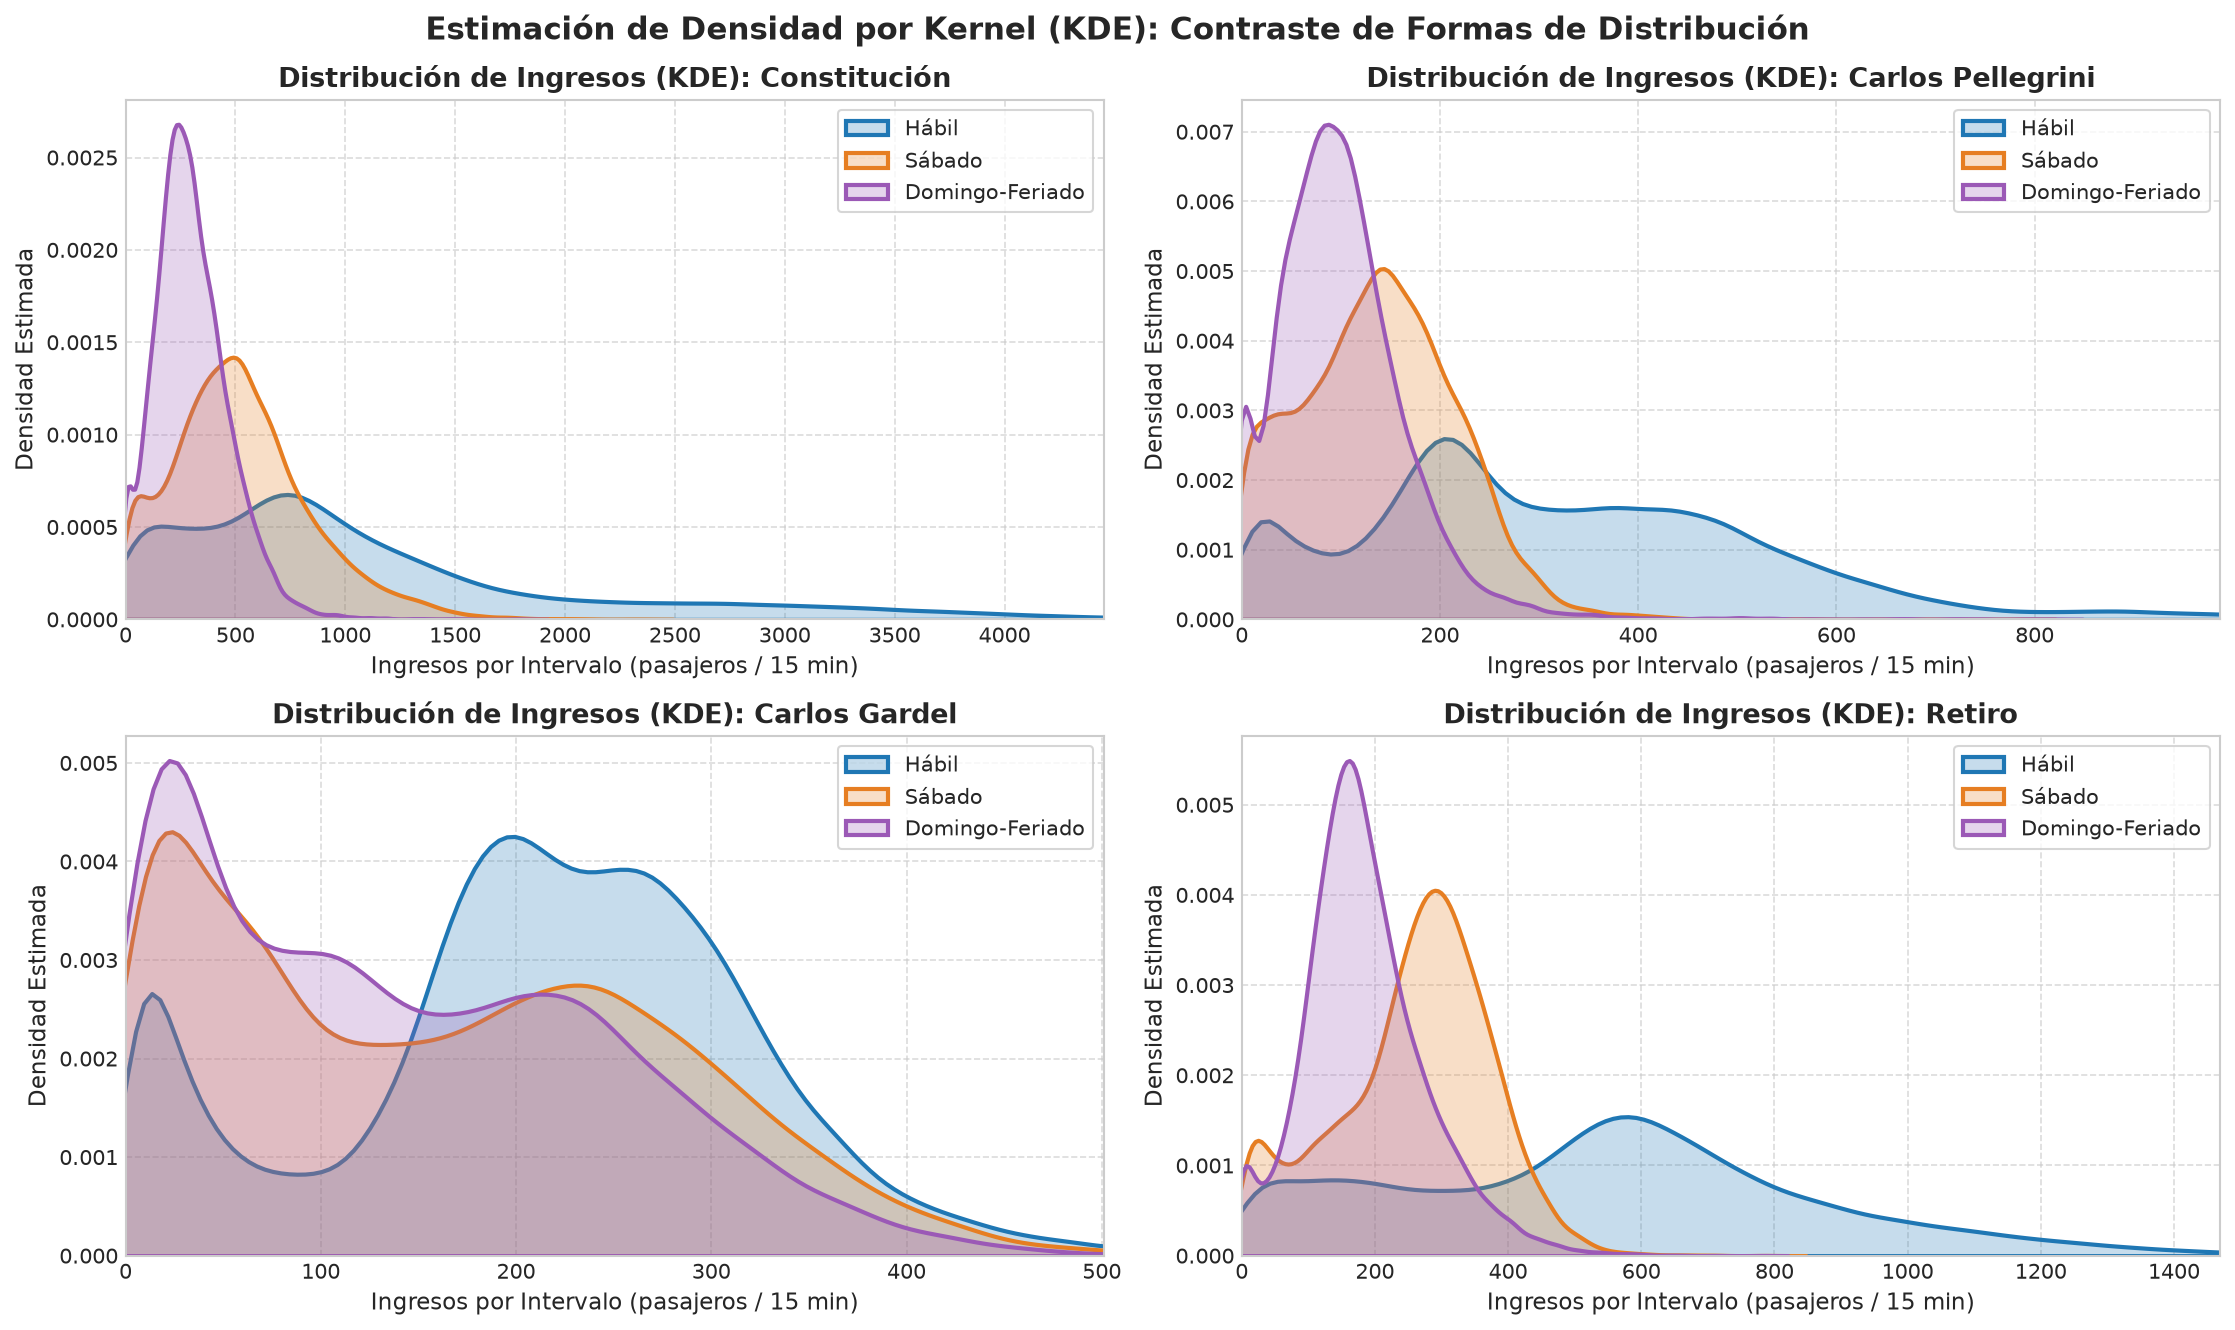

In [17]:
kde_estaciones = ['Constitución', 'Carlos Pellegrini', 'Carlos Gardel', 'Retiro']
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes = axes.flatten()

for i, est in enumerate(kde_estaciones):
    ax = axes[i]
    sub = df_service[df_service['estacion'] == est]
    habil_data = sub[sub['tipo_dia'] == 'Hábil']['ingresos']
    for t in TIPOS_DIA:
        sns.kdeplot(sub[sub['tipo_dia'] == t]['ingresos'], ax=ax, label=t, color=TIPO_COLORS[t],
                    fill=True, alpha=0.25, linewidth=2)

    ax.set_title(f'Distribución de Ingresos (KDE): {est}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Ingresos por Intervalo (pasajeros / 15 min)', fontsize=11)
    ax.set_ylabel('Densidad Estimada', fontsize=11)
    ax.set_xlim(left=0, right=np.percentile(habil_data, 99.5))
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper right', frameon=True)

plt.suptitle('Estimación de Densidad por Kernel (KDE): Contraste de Formas de Distribución', fontsize=15, fontweight='bold')
plt.tight_layout()
guardar_figura('05_kde_habil_vs_nolaborable.png')

### 6.2. Prueba de Kolmogorov-Smirnov (K-S 2 Muestras) para las 44 Estaciones
Se compara cada tipo de día no laborable con los días hábiles.
- **$H_0$:** La distribución empírica de demanda por 15 min es idéntica entre Días Hábiles y el tipo de día no laborable (Sábado; Domingo-Feriado).
- **$H_1$:** Las distribuciones son distintas (heterogeneidad).
- **$\alpha = 0.05$**.

*Esta prueba será reemplazada por el diseño de DM-04 (distancia de variación total con test de permutación).*

In [18]:
ALPHA = 0.05
ks_results = []
estaciones_unicas = df_15min[['linea', 'estacion']].drop_duplicates().sort_values(by=['linea', 'estacion'])

for _, row in estaciones_unicas.iterrows():
    l, st = row['linea'], row['estacion']
    s_est = df_15min[df_15min['estacion'] == st]
    sample_habil = s_est[s_est['tipo_dia'] == 'Hábil']['ingresos'].values
    rec = {'linea': l, 'estacion': st, 'n_habil': len(sample_habil)}
    for t in NO_LABORABLES:
        sample_t = s_est[s_est['tipo_dia'] == t]['ingresos'].values
        res = stats.ks_2samp(sample_habil, sample_t)
        rec.update({f'n_{t}': len(sample_t), f'd_{t}': res.statistic, f'p_{t}': res.pvalue,
                    f'rechaza_{t}': bool(res.pvalue < ALPHA)})
    ks_results.append(rec)

df_ks = pd.DataFrame(ks_results)
for t in NO_LABORABLES:
    print(f"Hábil vs {t}: se rechaza H0 en {df_ks[f'rechaza_{t}'].sum()} de {len(df_ks)} estaciones")

fmt_p = lambda p: "< 1e-15" if p < 1e-15 else f"{p:.4e}"
md_ks = "# Resultados de la Prueba de Kolmogorov-Smirnov (K-S 2 Muestras)\n\n"
md_ks += "### Fundamentación Estadística\n"
md_ks += "- **Hipótesis Nula ($H_0$):** La distribución empírica de demanda ($15\\text{ min}$) en la estación es idéntica entre Días Hábiles y el tipo de día no laborable comparado (Sábado; Domingo-Feriado).\n"
md_ks += "- **Hipótesis Alternativa ($H_1$):** Las distribuciones son distintas (demanda heterogénea).\n"
md_ks += f"- **Nivel de significancia:** $\\alpha = {ALPHA}$.\n\n"
md_ks += "**Resultado Global:** " + '; '.join(
    f"Hábil vs {t}: se rechaza $H_0$ en {df_ks[f'rechaza_{t}'].sum()} de {len(df_ks)} estaciones" for t in NO_LABORABLES) + ".\n\n"
md_ks += "| Línea | Estación | Muestra Hábil ($N$) | D Sábado | p-valor Sábado | D Domingo-Feriado | p-valor Domingo-Feriado |\n"
md_ks += "| :--- | :--- | :---: | :---: | :---: | :---: | :---: |\n"
for _, r in df_ks.iterrows():
    md_ks += (f"| {r['linea']} | {r['estacion']} | {r['n_habil']:,} | {r['d_Sábado']:.4f} | {fmt_p(r['p_Sábado'])} "
              f"| {r['d_Domingo-Feriado']:.4f} | {fmt_p(r['p_Domingo-Feriado'])} |\n")

guardar_tabla('05_resultados_kolmogorov_smirnov_44_estaciones.md', md_ks)

Hábil vs Sábado: se rechaza H0 en 44 de 44 estaciones
Hábil vs Domingo-Feriado: se rechaza H0 en 44 de 44 estaciones
Tabla guardada: output/tablas/05_resultados_kolmogorov_smirnov_44_estaciones.md


# Resultados de la Prueba de Kolmogorov-Smirnov (K-S 2 Muestras)

### Fundamentación Estadística
- **Hipótesis Nula ($H_0$):** La distribución empírica de demanda ($15\text{ min}$) en la estación es idéntica entre Días Hábiles y el tipo de día no laborable comparado (Sábado; Domingo-Feriado).
- **Hipótesis Alternativa ($H_1$):** Las distribuciones son distintas (demanda heterogénea).
- **Nivel de significancia:** $\alpha = 0.05$.

**Resultado Global:** Hábil vs Sábado: se rechaza $H_0$ en 44 de 44 estaciones; Hábil vs Domingo-Feriado: se rechaza $H_0$ en 44 de 44 estaciones.

| Línea | Estación | Muestra Hábil ($N$) | D Sábado | p-valor Sábado | D Domingo-Feriado | p-valor Domingo-Feriado |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| Línea A | Acoyte | 105,577 | 0.5813 | < 1e-15 | 0.7120 | < 1e-15 |
| Línea A | Alberti | 104,539 | 0.4060 | < 1e-15 | 0.6847 | < 1e-15 |
| Línea A | Carabobo | 103,964 | 0.5714 | < 1e-15 | 0.7166 | < 1e-15 |
| Línea A | Castro Barros | 104,728 | 0.6162 | < 1e-15 | 0.7526 | < 1e-15 |
| Línea A | Congreso | 105,157 | 0.6096 | < 1e-15 | 0.7361 | < 1e-15 |
| Línea A | Lima | 105,508 | 0.5985 | < 1e-15 | 0.7174 | < 1e-15 |
| Línea A | Loria | 105,297 | 0.5961 | < 1e-15 | 0.7263 | < 1e-15 |
| Línea A | Pasco | 102,620 | 0.5509 | < 1e-15 | 0.6902 | < 1e-15 |
| Línea A | Perú | 104,768 | 0.5336 | < 1e-15 | 0.5718 | < 1e-15 |
| Línea A | Piedras | 104,046 | 0.5764 | < 1e-15 | 0.6943 | < 1e-15 |
| Línea A | Plaza Miserere | 106,595 | 0.4841 | < 1e-15 | 0.6780 | < 1e-15 |
| Línea A | Plaza de Mayo | 96,924 | 0.7076 | < 1e-15 | 0.7101 | < 1e-15 |
| Línea A | Primera Junta | 104,166 | 0.5383 | < 1e-15 | 0.7176 | < 1e-15 |
| Línea A | Puán | 103,457 | 0.5557 | < 1e-15 | 0.7365 | < 1e-15 |
| Línea A | Río de Janeiro | 105,008 | 0.5890 | < 1e-15 | 0.7309 | < 1e-15 |
| Línea A | San José de Flores | 103,237 | 0.5004 | < 1e-15 | 0.6890 | < 1e-15 |
| Línea A | San Pedrito | 104,122 | 0.4100 | < 1e-15 | 0.6774 | < 1e-15 |
| Línea A | Sáenz Peña | 104,009 | 0.6589 | < 1e-15 | 0.7537 | < 1e-15 |
| Línea B | Callao (B) | 102,554 | 0.6380 | < 1e-15 | 0.7670 | < 1e-15 |
| Línea B | Carlos Gardel | 102,775 | 0.2655 | < 1e-15 | 0.3400 | < 1e-15 |
| Línea B | Carlos Pellegrini | 102,900 | 0.5015 | < 1e-15 | 0.6584 | < 1e-15 |
| Línea B | De los Incas | 101,120 | 0.6655 | < 1e-15 | 0.7571 | < 1e-15 |
| Línea B | Dorrego | 102,215 | 0.5799 | < 1e-15 | 0.7178 | < 1e-15 |
| Línea B | Echeverría | 100,169 | 0.6011 | < 1e-15 | 0.7129 | < 1e-15 |
| Línea B | Federico Lacroze | 104,369 | 0.4846 | < 1e-15 | 0.6151 | < 1e-15 |
| Línea B | Florida | 101,792 | 0.5794 | < 1e-15 | 0.6291 | < 1e-15 |
| Línea B | Juan Manuel de Rosas | 102,210 | 0.5583 | < 1e-15 | 0.7261 | < 1e-15 |
| Línea B | Leandro N. Alem | 101,570 | 0.7620 | < 1e-15 | 0.7568 | < 1e-15 |
| Línea B | Malabia | 102,411 | 0.6383 | < 1e-15 | 0.7466 | < 1e-15 |
| Línea B | Medrano | 102,827 | 0.6624 | < 1e-15 | 0.7732 | < 1e-15 |
| Línea B | Pasteur | 102,472 | 0.4668 | < 1e-15 | 0.7715 | < 1e-15 |
| Línea B | Pueyrredón | 102,655 | 0.4358 | < 1e-15 | 0.7204 | < 1e-15 |
| Línea B | Tronador | 101,003 | 0.6395 | < 1e-15 | 0.7586 | < 1e-15 |
| Línea B | Uruguay | 102,305 | 0.6529 | < 1e-15 | 0.7399 | < 1e-15 |
| Línea B | Ángel Gallardo | 102,459 | 0.6387 | < 1e-15 | 0.7232 | < 1e-15 |
| Línea C | Avenida de Mayo | 103,994 | 0.6683 | < 1e-15 | 0.7413 | < 1e-15 |
| Línea C | Constitución | 101,487 | 0.3635 | < 1e-15 | 0.6236 | < 1e-15 |
| Línea C | Diagonal Norte | 103,769 | 0.5830 | < 1e-15 | 0.7169 | < 1e-15 |
| Línea C | General San Martín | 103,631 | 0.5692 | < 1e-15 | 0.7063 | < 1e-15 |
| Línea C | Independencia | 105,671 | 0.5614 | < 1e-15 | 0.6410 | < 1e-15 |
| Línea C | Lavalle | 103,731 | 0.4977 | < 1e-15 | 0.6257 | < 1e-15 |
| Línea C | Moreno | 103,614 | 0.6380 | < 1e-15 | 0.7412 | < 1e-15 |
| Línea C | Retiro | 101,814 | 0.6020 | < 1e-15 | 0.6626 | < 1e-15 |
| Línea C | San Juan | 101,068 | 0.6400 | < 1e-15 | 0.7641 | < 1e-15 |


### 6.3. Presión de Andén en Días No Laborables
Identificación de ventanas horarias críticas de fin de semana donde el flujo de molinete compromete la capacidad nominal de despacho de formaciones.

**Supuesto del umbral:** en días no laborables la frecuencia de despacho oscila entre 8 y 12 minutos; una formación típica (5 coches) alberga ~900 a 1.000 pasajeros a capacidad de diseño. Con 1,2 a 1,5 trenes por ventana de 15 min por sentido, la capacidad de absorción de ingreso sostenido sin saturación de andén se estima en ~1.200 a 1.500 pax / 15 min. Se adopta **1.200 pax / 15 min** como umbral.

In [19]:
UMBRAL_PRESION = 1200

criticos_nolab = df_15min[(df_15min['tipo_dia'] != 'Hábil') & (df_15min['ingresos'] >= UMBRAL_PRESION)].copy()
top_criticos = criticos_nolab.groupby(['linea', 'estacion', 'ventana_15min'])['ingresos'].agg(
    Ocurrencias='count',
    Ingreso_Maximo='max',
    Ingreso_Promedio='mean'
).reset_index().sort_values(by='Ingreso_Maximo', ascending=False)

md_presion = "# Análisis de Presión de Andén en Días No Laborables\n\n"
md_presion += f"Se identificaron los intervalos de 15 minutos en fines de semana y feriados donde la tasa de afluencia por molinete superó la capacidad nominal de absorción de andén estimada (umbral crítico: **{UMBRAL_PRESION:,} pasajeros por ventana de 15 min**):\n\n"
md_presion += f"- **Total de eventos de alta presión registrados (2014-2019):** {len(criticos_nolab):,} intervalos.\n"
eventos_por_estacion = criticos_nolab.groupby(['linea', 'estacion']).size().sort_values(ascending=False)
eventos_por_tipo_dia = criticos_nolab['tipo_dia'].value_counts()
md_presion += "- **Estaciones con eventos:** " + ', '.join(f"{est} ({lin}): {n:,}" for (lin, est), n in eventos_por_estacion.items()) + ".\n"
md_presion += "- **Distribución por tipo de día:** " + ', '.join(f"{t}: {n:,}" for t, n in eventos_por_tipo_dia.items()) + ".\n"
pct_manana = (criticos_nolab['ventana_15min'].between('07:00', '09:45')).mean() * 100
md_presion += f"- **Franja horaria:** {pct_manana:.1f}% de los eventos ocurre entre las 07:00 y las 10:00 (ventanas 07:00 a 09:45).\n"
eventos_por_anio = criticos_nolab.groupby('anio').size().reindex(sorted(df_15min['anio'].unique()), fill_value=0)
md_presion += "- **Evolución anual:** " + ', '.join(f"{a}: {n:,}" for a, n in eventos_por_anio.items()) + ".\n\n"
md_presion += "### Ventanas Horarias de Mayor Presión de Andén (Top 15 Críticas)\n\n"
md_presion += "| Línea | Estación | Ventana Horaria (15m) | Ocurrencias Históricas | Ingreso Máximo (pax/15m) | Ingreso Promedio en Evento |\n"
md_presion += "| :--- | :--- | :---: | :---: | :---: | :---: |\n"
for _, r in top_criticos.head(15).iterrows():
    md_presion += f"| {r['linea']} | **{r['estacion']}** | {r['ventana_15min']} | {r['Ocurrencias']:,} | **{r['Ingreso_Maximo']:,.0f}** | {r['Ingreso_Promedio']:,.1f} |\n"

guardar_tabla('06_presion_anden_analisis.md', md_presion)

Tabla guardada: output/tablas/06_presion_anden_analisis.md


# Análisis de Presión de Andén en Días No Laborables

Se identificaron los intervalos de 15 minutos en fines de semana y feriados donde la tasa de afluencia por molinete superó la capacidad nominal de absorción de andén estimada (umbral crítico: **1,200 pasajeros por ventana de 15 min**):

- **Total de eventos de alta presión registrados (2014-2019):** 750 intervalos.
- **Estaciones con eventos:** Constitución (Línea C): 750.
- **Distribución por tipo de día:** Sábado: 727, Domingo-Feriado: 23.
- **Franja horaria:** 92.1% de los eventos ocurre entre las 07:00 y las 10:00 (ventanas 07:00 a 09:45).
- **Evolución anual:** 2014: 18, 2015: 41, 2016: 75, 2017: 140, 2018: 258, 2019: 218.

### Ventanas Horarias de Mayor Presión de Andén (Top 15 Críticas)

| Línea | Estación | Ventana Horaria (15m) | Ocurrencias Históricas | Ingreso Máximo (pax/15m) | Ingreso Promedio en Evento |
| :--- | :--- | :---: | :---: | :---: | :---: |
| Línea C | **Constitución** | 08:15 | 109 | **2,364** | 1,416.9 |
| Línea C | **Constitución** | 07:45 | 58 | **2,296** | 1,378.6 |
| Línea C | **Constitución** | 08:45 | 61 | **2,125** | 1,394.7 |
| Línea C | **Constitución** | 09:15 | 68 | **2,102** | 1,357.2 |
| Línea C | **Constitución** | 08:30 | 106 | **2,091** | 1,427.6 |
| Línea C | **Constitución** | 09:30 | 59 | **2,013** | 1,379.8 |
| Línea C | **Constitución** | 08:00 | 87 | **1,973** | 1,452.0 |
| Línea C | **Constitución** | 07:00 | 25 | **1,941** | 1,370.9 |
| Línea C | **Constitución** | 09:45 | 17 | **1,856** | 1,367.9 |
| Línea C | **Constitución** | 07:30 | 23 | **1,821** | 1,375.9 |
| Línea C | **Constitución** | 07:15 | 16 | **1,787** | 1,341.3 |
| Línea C | **Constitución** | 09:00 | 62 | **1,758** | 1,343.9 |
| Línea C | **Constitución** | 06:45 | 6 | **1,745** | 1,431.0 |
| Línea C | **Constitución** | 10:15 | 4 | **1,730** | 1,405.5 |
| Línea C | **Constitución** | 10:30 | 12 | **1,488** | 1,286.0 |


Gráfico guardado: output/graficos/06_presion_anden_ventanas_criticas.png


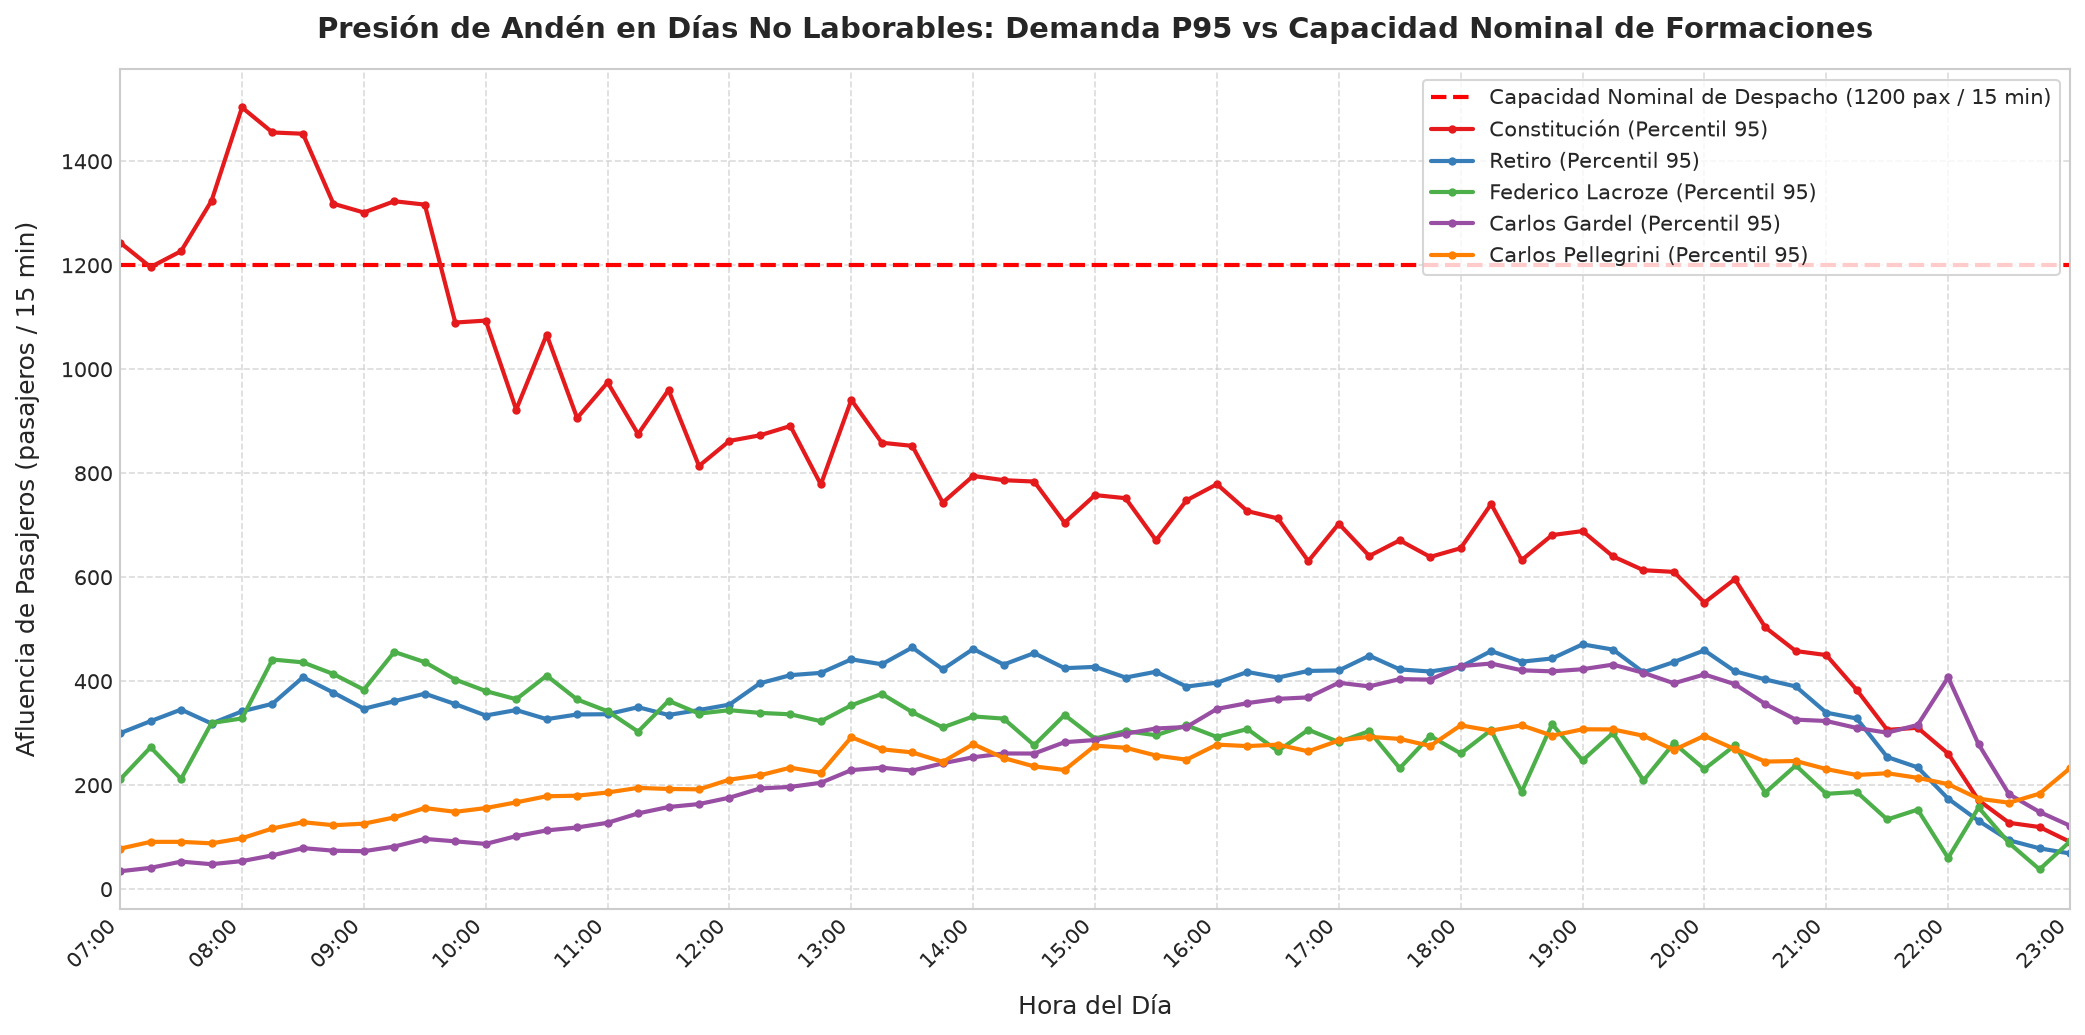

In [20]:
congested_stations = ['Constitución', 'Retiro', 'Federico Lacroze', 'Carlos Gardel', 'Carlos Pellegrini']
sub_presion = df_service[(df_service['tipo_dia'] != 'Hábil') & (df_service['estacion'].isin(congested_stations))]

hourly_presion = sub_presion.groupby(['estacion', 'hora_decimal'])['ingresos'].agg(
    P95=lambda x: np.percentile(x, 95),
    Maximo='max'
).reset_index()
hourly_presion = hourly_presion[(hourly_presion['hora_decimal'] >= 7.0) & (hourly_presion['hora_decimal'] <= 23.0)]

fig, ax = plt.subplots(figsize=(14, 7))
ax.axhline(UMBRAL_PRESION, color='red', linestyle='--', linewidth=2,
           label=f'Capacidad Nominal de Despacho ({UMBRAL_PRESION} pax / 15 min)')

station_palette = sns.color_palette("Set1", len(congested_stations))
for i, est in enumerate(congested_stations):
    sub_st = hourly_presion[hourly_presion['estacion'] == est].sort_values(by='hora_decimal')
    ax.plot(sub_st['hora_decimal'], sub_st['P95'], marker='o', markersize=3, label=f'{est} (Percentil 95)',
            color=station_palette[i], linewidth=2)

ax.set_title('Presión de Andén en Días No Laborables: Demanda P95 vs Capacidad Nominal de Formaciones', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Hora del Día', fontsize=12, labelpad=10)
ax.set_ylabel('Afluencia de Pasajeros (pasajeros / 15 min)', fontsize=12, labelpad=10)
ax.set_xlim(7.0, 23.0)
step_ticks = np.arange(7, 24, 1)
ax.set_xticks(step_ticks)
ax.set_xticklabels([f'{int(h):02d}:00' for h in step_ticks], rotation=45, ha='right', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(loc='upper right', frameon=True, fontsize=10)

plt.tight_layout()
guardar_figura('06_presion_anden_ventanas_criticas.png')

## 7. Conclusiones y Resumen para Metodología
1. **Heterogeneidad en las 44 estaciones:** La prueba de Kolmogorov-Smirnov rechaza $H_0$ en las 44 estaciones tanto para Hábil frente a Sábado ($D$ entre 0,27 y 0,76) como para Hábil frente a Domingo-Feriado ($D$ entre 0,34 y 0,77), con $p < 10^{-15}$. *Este contraste será reemplazado por el diseño de DM-04.*
2. **Asimetría Territorial y Ratios de Retención:** La red retiene el 38,58% de la demanda hábil los sábados y el 19,60% los domingos y feriados. El promedio enmascara brechas extremas entre el Microcentro (en Domingo-Feriado, Florida retiene el 9,04% y Diagonal Norte el 9,18%; los sábados, Diagonal Norte el 18,70% y Plaza de Mayo el 18,76%) y los polos recreativos o de transbordo (Carlos Gardel retiene el 72,29% los sábados y el 54,14% los domingos y feriados). Constitución mantiene el mayor volumen absoluto: 37.173 pax/día los sábados y 17.761 los domingos y feriados.
3. **Tres regímenes de demanda:** Sábados y domingos-feriados difieren tanto en volumen (retención de 38,58% frente a 19,60%) como en distribución horaria (meseta del sábado cerca del mediodía; máximo del domingo al atardecer). Dentro de Domingo-Feriado, domingos (18,78%) y feriados (21,95%) tienen niveles comparables, lo que respalda su agrupación (DM-03).
4. **Presión de Andén Localizada:** Con el umbral supuesto de 1.200 pax / 15 min, los 750 intervalos críticos en días no laborables ocurren todos en Constitución: el 92,1% entre las 07:00 y las 10:00, 727 en sábados y 23 en domingos y feriados, con tendencia creciente en el período (de 18 eventos en 2014 a 258 en 2018). El resultado señala la persistencia del viaje laboral matutino de los sábados en la cabecera de la Línea C. *Esta métrica será reemplazada por la frecuencia mínima requerida (DM-05).*

La síntesis interpretativa extendida para la entrega escrita se encuentra en `output/resumen_metodologia.md`.